# Scam classifier: simulated calls to PhayaThaiBERT

Builds a per-turn dataset from `dataset/*.jsonl` and trains two classifiers:

- the gate: scam or not scam
- the type: which of the 5 spec types, for scam rows only

Each gets a TF-IDF + logistic regression baseline, a fine-tuned PhayaThaiBERT
(`clicknext/phayathaibert`) a fine-tuned BGE-M3 (`BAAI/bge-m3`) and a fine-tuned WangchanBERTa
(`airesearch/wangchanberta-base-att-spm-uncased`). Valid picks the epoch; test is scored once.

| Part | Steps |
|---|---|
| A. Data preparation | 1 load, 2 leakage EDA, 3 clean, 4 labels, 5 groups, 6 split, 6b rows per turn, 7 export |
| B. Modeling | 8 baseline, 9 tokens, 10-11 fine-tune, 11b BGE-M3, 11c WangchanBERTa, 12 cross-validation, 13 test scores, 14 inference |

Run part A, then part B, in one kernel.

## Setup

```
pip install torch --index-url https://download.pytorch.org/whl/cu128
pip install -e ".[ml]"
```

In [1]:
import json
import random
import re
import shutil
from bisect import bisect_right
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pythainlp.tokenize import word_tokenize

from nlp_core.text import normalize_text

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "pyproject.toml").exists()
)
PROCESSED = ROOT / "data" / "processed_balanced"  # part A writes it, part B reads it
FIGURES = ROOT / "notebooks" / "figures"  # every chart and table as a png, one folder per step

pd.set_option("display.max_colwidth", 200)

# Each class and each model keeps one colour in every chart.
CLASS_COLORS = {"Not a Scam": "tab:blue", "Scam": "tab:orange"}
MODEL_COLORS = {
    "majority": "tab:red", "random": "tab:purple", "tfidf_logreg": "tab:gray",
    "phayathaibert": "tab:green", "bge_m3": "tab:brown", "wangchanberta": "tab:olive",
}  # fmt: skip
plt.rcParams["figure.dpi"] = 110
# DejaVu Sans has no Thai letters; matplotlib falls back to the next font for them.
plt.rcParams["font.family"] = ["DejaVu Sans", "Leelawadee UI", "Tahoma"]


def thai_words(text: str) -> list[str]:
    """Split Thai text into words with PyThaiNLP's newmm, without spaces and punctuation."""
    words = word_tokenize(text, engine="newmm", keep_whitespace=False)
    return [word for word in words if not re.fullmatch(r"[\W_]+", word)]


def figure_path(name: str) -> Path:
    """FIGURES/<prefix>/<name>.png for names like step13_..., FIGURES/models/ for the rest."""
    prefix = name.split("_")[0]
    folder = FIGURES / (prefix if prefix.startswith(("step", "partb")) else "models")
    folder.mkdir(parents=True, exist_ok=True)
    return folder / f"{name}.png"


def save_chart(name: str) -> None:
    """Save the current chart as a png in its step folder, then show it."""
    plt.savefig(figure_path(name), dpi=150, bbox_inches="tight")
    plt.show()


def save_table(table: pd.DataFrame | pd.Series, name: str) -> pd.DataFrame | pd.Series:
    """Save a table as a png in its step folder and return it, so the cell still shows it."""
    frame = table.to_frame() if isinstance(table, pd.Series) else table
    frame = frame.round(3)
    rows = [" / ".join(map(str, i)) if isinstance(i, tuple) else str(i) for i in frame.index]
    columns = [" / ".join(map(str, c)) if isinstance(c, tuple) else str(c) for c in frame.columns]
    fig, ax = plt.subplots(figsize=(1.5 * (len(columns) + 1), 0.3 * (len(rows) + 1)))
    ax.axis("off")
    ax.table(
        cellText=frame.astype(str).to_numpy(), rowLabels=rows, colLabels=columns,
        loc="center", cellLoc="center",
    )  # fmt: skip
    fig.savefig(figure_path(name), dpi=150, bbox_inches="tight")
    plt.close(fig)
    return table


print("repo root:", ROOT)

repo root: D:\text_analytics\Callas


# Part A. Data preparation

```mermaid
flowchart TD
    IN[("dataset/*.jsonl<br/>one file per call type")] --> S1
    S1["<b>Step 1. Load</b><br/>drop rejected calls<br/>mask every tagged value as [LABEL]<br/>read each call's scenario"] --> S2
    S2["<b>Step 2. EDA: leakage</b><br/>notes, label words, shortcut words,<br/>placeholders per type"] --> S3
    S3["<b>Step 3. Clean</b><br/>remove notes, normalize the Thai,<br/>letters by role: A receiver, B caller"] --> C3
    C3{"Step 3 checks"} -->|"bracket left, names a label,<br/>fewer than 2 turns,<br/>scam call with no start"| DROP[["dropped, ids printed"]]
    C3 --> S4
    S4["<b>Step 4. Labels</b><br/>label_scam, label_type (5 spec types)<br/>drop exact duplicate calls"] --> S4B
    S4B["<b>Step 4b. Class sizes</b><br/>keep every call, no downsampling<br/>SKIP_TYPES leaves a type out"] --> S5
    S5["<b>Step 5. Groups</b><br/>one group per scenario"] --> S6
    S6["<b>Step 6. Split by scenario</b><br/>StratifiedGroupKFold<br/>train 70, valid 15, test 15"] --> S6B
    S6B["<b>Step 6b. One row per turn</b><br/>row = every line from the start<br/>of the call up to the turn,<br/>oldest lines cut past MAX_TOKENS"] --> LAB
    LAB["<b>Label</b><br/>scam: every turn from scam_start_turn on<br/>safe: everything else"] --> S7
    S7["<b>Step 7. Export</b><br/>train, valid, test, dataset.csv: rows"] --> OUT[("data/processed_balanced/<br/>read by part B")]
```

## Input format

One JSON call per line, one file per call type. The next cell reads them:

- `is_rejected` drops calls the studio's checks or a reviewer rejected.
- `jsonl_row` maps speaker A to the caller and B to the receiver.
- `masked_turns` masks every tagged entity as `[LABEL]`, such as `[PERSON]` or `[PHONE]`.
- `scenario_key` names the scenario `<type>/<name>`; step 5 groups by it.

In [2]:
from nlp_core.types import ENTITY_LABELS

MASKED_LABELS = ENTITY_LABELS


def load_jsonl(path: Path) -> tuple[pd.DataFrame, int]:
    """Read one file's calls as raw rows, and count the rejected calls left out."""
    rows, rejected = [], 0
    for number, line in enumerate(path.read_text(encoding="utf-8").splitlines(), start=1):
        if not line.strip():
            continue
        try:
            call = json.loads(line)
            if is_rejected(call):
                rejected += 1
                continue
            rows.append(jsonl_row(call))
        except (KeyError, ValueError) as error:
            raise ValueError(f"{path.name} line {number}: {error!r}") from error
    return pd.DataFrame(rows), rejected


def is_rejected(call: dict) -> bool:
    """Say whether the studio's checks or a reviewer on the /dataset page rejected the call."""
    return call.get("dataset") == "real_rejected" or call.get("review_status") == "rejected"


def jsonl_row(call: dict) -> dict:
    """Turn one call into a raw row: its masked turns as (role, text), its labels and ids."""
    roles = {"A": "caller", "B": "receiver"}  # in a generated call A is the caller
    unknown = sorted({turn["speaker"] for turn in call["speaker_turns"]} - set(roles))
    if unknown:
        raise ValueError(f"{call['id']}: unknown speakers {unknown}")
    scam = bool(call["label_scam"])
    return {
        "turns": [(roles[turn["speaker"]], turn["text"]) for turn in masked_turns(call)],
        "scam_class": "Scam" if scam else "Not a Scam",
        "scam_type": (call.get("label_type") or "") if scam else "",
        "source": "simulated",
        "scam_start_turn": call.get("scam_start_turn") if scam else None,
        "call_id": call["id"],
        "scam_outcome": (call.get("scam_outcome") or None) if scam else None,
        "scam_outcome_source": (call.get("scam_outcome_source") or None) if scam else None,
        "scenario": scenario_key(call),
    }


def masked_turns(call: dict) -> list[dict]:
    """Replace each tagged value in the call's turns with "[LABEL]".

    Entity positions count characters in call["text"], the turns joined as "{speaker}: {text}".
    """
    turns = call["speaker_turns"]
    if call["text"] != "\n".join(f"{turn['speaker']}: {turn['text']}" for turn in turns):
        raise ValueError(f"{call['id']}: text is not its speaker turns joined")
    turn_starts, position = [], 0  # where each turn's words start in call["text"]
    for turn in turns:
        turn_starts.append(position + len(turn["speaker"]) + 2)
        position = turn_starts[-1] + len(turn["text"]) + 1
    texts = [turn["text"] for turn in turns]
    replaced = [ent for ent in call.get("entities") or [] if ent["label"] in MASKED_LABELS]
    masked_from = len(call["text"])  # values are masked from the end
    for ent in sorted(replaced, key=lambda ent: ent["start"], reverse=True):
        if call["text"][ent["start"] : ent["end"]] != ent["text"]:
            raise ValueError(
                f"{call['id']}: {ent['label']} {ent['text']!r} is not at {ent['start']}"
            )
        if ent["end"] > masked_from:
            raise ValueError(f"{call['id']}: {ent['label']} {ent['text']!r} overlaps another value")
        turn_no = bisect_right(turn_starts, ent["start"]) - 1
        begin = ent["start"] - turn_starts[turn_no]
        finish = ent["end"] - turn_starts[turn_no]
        if turn_no < 0 or begin < 0 or finish > len(turns[turn_no]["text"]):
            raise ValueError(f"{call['id']}: {ent['label']} {ent['text']!r} is not inside one turn")
        texts[turn_no] = texts[turn_no][:begin] + f"[{ent['label']}]" + texts[turn_no][finish:]
        masked_from = ent["start"]
    return [{**turn, "text": text} for turn, text in zip(turns, texts, strict=True)]


def scenario_key(call: dict) -> str:
    """Return the call's scenario as "<type>/<name>"; a call without one is its own scenario."""
    scenario = call.get("scenario")
    name = scenario.get("key") if isinstance(scenario, dict) else scenario
    call_type = (call.get("label_type") or "scam_other") if call["label_scam"] else "normal"
    return f"{call_type}/{name or 'call_' + str(call['id'])}"


def call_text(turns: list[tuple[str, str]]) -> str:
    """All the words of a call, for the checks that look for a word anywhere in it."""
    return " ".join(text for _, text in turns)

## Step 1. Data loading

Reads every `dataset/*.jsonl` file, one row per call. Stops on a missing file, an unreadable
line (it names the file and line) or a repeated call id.

Tables: calls per file, scam outcome per type, scenarios per type. Chart: calls per class.

=== Calls per file ===
                             calls  rejected (dropped)  kept
fake_authority.jsonl           259                   0   259
investment.jsonl               271                  92   179
lottery.jsonl                  245                   0   245
normal.jsonl                   227                   0   227
phishing_otp.jsonl             277                   0   277
romance.jsonl                  435                  95   340
sonnet_fake_authority.jsonl     70                   0    70
sonnet_investment.jsonl         70                   0    70
sonnet_lottery.jsonl            70                   0    70
sonnet_normal.jsonl            364                   0   364
sonnet_phishing_otp.jsonl       70                   0    70
sonnet_romance.jsonl            70                   0    70
(2241, 9)
=== Scam outcome per type ===
scam_outcome    none  safe  scammed
type                               
fake_authority     0   186      143
investment         0   137      112


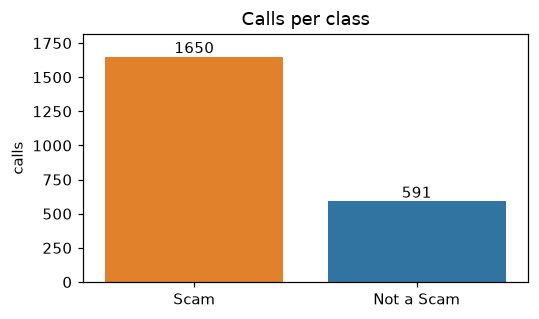

,turns,scam_class,scam_type,source,scam_start_turn,call_id,scam_outcome,scam_outcome_source,scenario
0,"[(caller, สวัสดีครับ ติดต่อจาก [ORG] ครับ เรียนคุณ [PERSON] ครับ ไม่ต้องตกใจครับ ทางเราโทรมาเพื่อแจ้งข่าวดีเกี่ยวกับเงินคืนภาษีของท่านครับ), (receiver, สวัสดีครับ ภาษีคืนเหรอครับ แล้วมียอดเท่าไหร่...",Scam,fake_authority,simulated,0.0,fake_authority_00050,safe,inferred,fake_authority/revenue_tax
1,"[(caller, สวัสดีค่ะ ทางเราติดต่อมาจาก [ORG] นะคะ ขออนุญาตสอบถามว่า เป็นคุณ [PERSON] ใช่ไหมคะ), (receiver, ใช่ครับ ผมเอง มีธุระอะไรหรือครับ), (caller, ไม่ตองตกใจนะคะ ทางเราโทรมาแจ้งว่าต้องเปลี่ยนมิ...",Scam,fake_authority,simulated,2.0,fake_authority_00051,safe,inferred,fake_authority/fake_mea_meter_change
2,"[(caller, สวัสดีค่ะ ติดต่อจาก [ORG] นะคะ เรียกสายคุณ [PERSON] ค่ะ), (receiver, สวัสดีครับ ผมเอง มีธุระอะไรหรือครับ), (caller, คือทางเราโทรมาแจ้งว่าคุณ [PERSON] มีสิทธิ์ได้รับเงินอุดหนุนจากรัฐบาลนะ...",Scam,fake_authority,simulated,4.0,fake_authority_00052,safe,inferred,fake_authority/gov_stimulus_data_scam


In [3]:
DATA_DIR = ROOT / "dataset"
DATA_FILES = sorted(DATA_DIR.glob("*.jsonl"))
if not DATA_FILES:
    raise FileNotFoundError(f"no *.jsonl file in {DATA_DIR}")
loaded, rejected = {}, {}
for path in DATA_FILES:
    loaded[path.name], rejected[path.name] = load_jsonl(path)
print("=== Calls per file ===")
print(
    save_table(
        pd.DataFrame(
            {
                "calls": {name: len(rows) + rejected[name] for name, rows in loaded.items()},
                "rejected (dropped)": rejected,
                "kept": {name: len(rows) for name, rows in loaded.items()},
            }
        ),
        "step01_calls_per_file",
    ).to_string()
)
raw = pd.concat(loaded.values(), ignore_index=True)

repeated_id = raw["call_id"].duplicated(keep=False)
if repeated_id.any():
    raise ValueError(
        f"call ids in more than one row: {sorted(set(raw.loc[repeated_id, 'call_id']))[:5]}"
    )

raw["scam_type"] = raw["scam_type"].fillna("").astype(str).str.strip()
raw["scam_start_turn"] = pd.to_numeric(raw["scam_start_turn"], errors="coerce")

print(raw.shape)
print("=== Scam outcome per type ===")
print(
    save_table(
        pd.crosstab(
            raw["scam_type"].replace("", "normal"), raw["scam_outcome"].fillna("none")
        ).rename_axis(index="type", columns="scam_outcome"),
        "step01_outcomes_per_type",
    ).to_string()
)
call_type = raw["scam_type"].replace("", "normal")
print("=== Scenarios per type ===")
print(
    save_table(
        raw.groupby(call_type)["scenario"]
        .agg(scenarios="nunique", calls="size")
        .rename_axis("type"),
        "step01_scenarios_per_type",
    ).to_string()
)

fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(data=raw, x="scam_class", hue="scam_class", palette=CLASS_COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container)
ax.set(title="Calls per class", xlabel="", ylabel="calls")
ax.margins(y=0.1)
plt.tight_layout()
save_chart("step01_calls_per_class")

raw.head(3)

## Step 2. EDA: data leakage

Leakage is a clue in the input that real calls will not have.

- A count of non-speech notes and label words (`LABEL_WORDS`); step 3 cleans or drops them.
- `SHORTCUT_WORDS`: keyword frequency per class, matched on PyThaiNLP word tokens.
- Heatmap: the share of each call type that mentions each entity placeholder. A placeholder found in
  one type only is a shortcut too.

calls with a note that is not speech: 2, with a word that names a label: 2 (step 3 cleans or drops them)


,% of Not a Scam calls,% of Scam calls
มิจฉาชีพ,4.1,14.5
แอบอ้าง,1.7,1.3
หลอกลวง,0.0,0.3
ต้มตุ๋น,0.0,0.0
แก๊ง,6.3,1.0
คอลเซ็นเตอร์,6.8,1.2
OTP,3.0,5.1


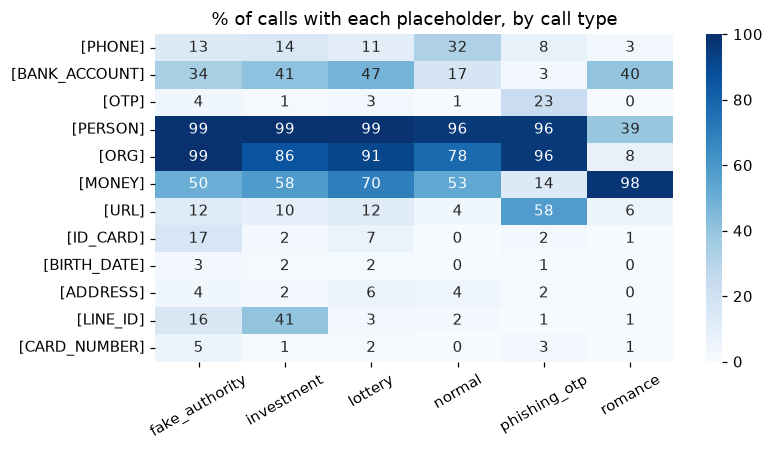

In [4]:
_LABELS = "|".join(MASKED_LABELS)
PLACEHOLDER = re.compile(rf"\[(?:{_LABELS})\]")
BRACKET_NOTE = re.compile(rf"\[(?!(?:{_LABELS})\])[^\]]*\]")
STAGE_NOTE = re.compile(r"\((?:เสียง|คนอื่น|ชาย|หญิง)[^)]*\)")
LABEL_WORDS = re.compile(
    r"scam(?:mer)?s?|phishing|impersonat\w*|fraud\w*|fake_authority|phishing_otp|สแกม|ฟิชชิ่ง",
    re.IGNORECASE,
)
SHORTCUT_WORDS = ("มิจฉาชีพ", "แอบอ้าง", "หลอกลวง", "ต้มตุ๋น", "แก๊ง", "คอลเซ็นเตอร์", "OTP")

spoken = raw["turns"].map(call_text)
has_note = spoken.str.contains(BRACKET_NOTE) | spoken.str.contains(STAGE_NOTE)
names_label = spoken.str.contains(LABEL_WORDS)
print(
    f"calls with a note that is not speech: {has_note.sum()}, "
    f"with a word that names a label: {names_label.sum()} (step 3 cleans or drops them)"
)

words = spoken.map(lambda text: set(thai_words(text)))
shortcuts = (
    pd.DataFrame({word: [word in call_words for call_words in words] for word in SHORTCUT_WORDS})
    .groupby(raw["scam_class"])
    .mean()
    .T.mul(100)
    .round(1)
)
shortcuts.columns = [f"% of {class_name} calls" for class_name in shortcuts.columns]
display(save_table(shortcuts, "step02_shortcut_words"))

placeholders = (
    pd.DataFrame(
        {f"[{label}]": spoken.str.contains(f"[{label}]", regex=False) for label in MASKED_LABELS}
    )
    .groupby(raw["scam_type"].replace("", "normal"))
    .mean()
    .T.mul(100)
)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(placeholders, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=ax)
ax.set(title="% of calls with each placeholder, by call type", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
save_chart("step02_placeholders_by_type")

### Chi-squared feature selection: words that separate the classes

A binary bag-of-words document-term matrix (PyThaiNLP `newmm` tokens, `CountVectorizer`), then
the 20 words with the highest chi-squared score between the classes,
each with the share of scam calls and normal calls that say it. A word in almost every call of
one class, such as a greeting template, is a shortcut the model can learn instead of the scam.
The fix is more varied calls, not removing the word.

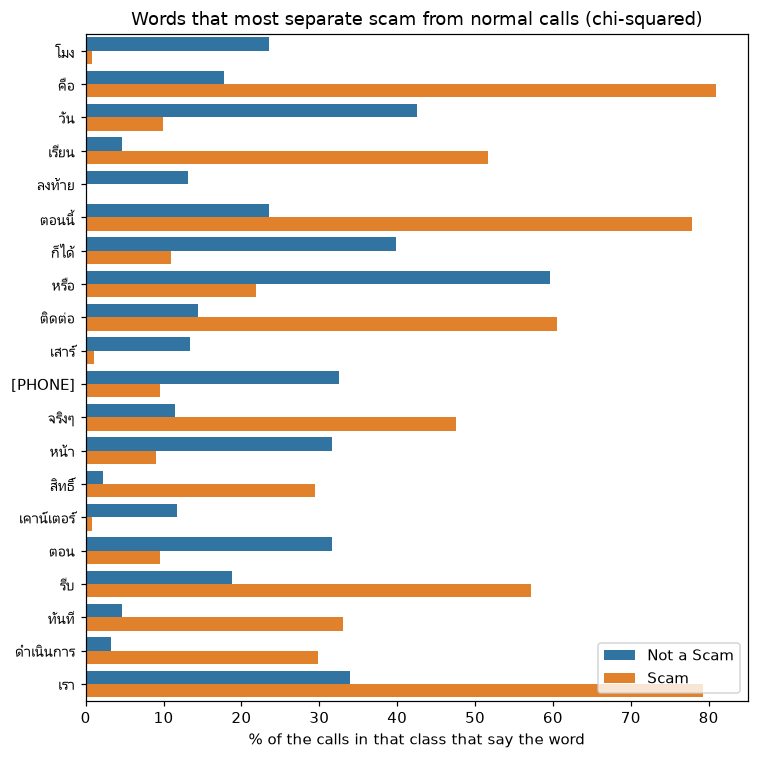

,chi2,% of scam calls,% of normal calls
word,,,
โมง,327.6,0.8,23.5
คือ,270.3,81.0,17.8
วัน,252.2,9.9,42.6
เรียน,243.4,51.6,4.7
ลงท้าย,204.0,0.2,13.2
ตอนนี้,202.4,77.9,23.5
ก็ได้,194.9,11.0,39.9
หรือ,193.3,21.9,59.6
ติดต่อ,191.7,60.5,14.4


In [5]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

vectorizer = CountVectorizer(
    tokenizer=thai_words, token_pattern=None, lowercase=False, binary=True, min_df=10
)
doc_term_matrix = vectorizer.fit_transform(spoken)
is_scam_call = raw["scam_class"].eq("Scam").to_numpy()
chi2_score, _ = chi2(doc_term_matrix, is_scam_call)
word_share = (
    pd.DataFrame(
        {
            "word": vectorizer.get_feature_names_out(),
            "chi2": chi2_score,
            "% of scam calls": np.asarray(doc_term_matrix[is_scam_call].mean(axis=0)).ravel() * 100,
            "% of normal calls": np.asarray(doc_term_matrix[~is_scam_call].mean(axis=0)).ravel()
            * 100,
        }
    )
    .nlargest(20, "chi2")
    .set_index("word")
    .round(1)
)

word_share_long = (
    word_share.rename(columns={"% of normal calls": "Not a Scam", "% of scam calls": "Scam"})
    .reset_index()
    .melt(id_vars="word", value_vars=["Not a Scam", "Scam"], var_name="class", value_name="share")
)
fig, ax = plt.subplots(figsize=(7, 7))
sns.barplot(data=word_share_long, x="share", y="word", hue="class", palette=CLASS_COLORS, ax=ax)
ax.set(
    title="Words that most separate scam from normal calls (chi-squared)",
    xlabel="% of the calls in that class that say the word",
    ylabel="",
)
ax.legend(title=None, loc="lower right")
plt.tight_layout()
save_chart("step02_words_by_class")
save_table(word_share, "step02_words_by_class_table")

## Step 3. Text cleaning and normalization

1. Remove notes; placeholders stay.
2. Text normalization with `normalize_text` (Unicode NFC, then `pythainlp.util.normalize`: zero-width characters,
   repeated or misplaced vowels and tone marks), then one space between words.
3. Drop empty turns and join turns of the same speaker.
4. Write `A: ...` / `B: ...` lines with A the receiver and B the caller, as the app does
   (`CallState._render`, `CALLED_PERSON`). Generated calls name the caller A, so the letters
   are swapped here.

In [6]:
def clean_turns_mapped(raw_turns: list[tuple[str, str]]) -> tuple[list[tuple[str, str]], list[int]]:
    """Clean the turns, and map each turn as written to its index in the cleaned turns."""
    turns: list[tuple[str, str]] = []
    where: list[int] = []
    for role, text in raw_turns:
        text = normalize_text(STAGE_NOTE.sub(" ", BRACKET_NOTE.sub(" ", text)))
        if not text:
            where.append(len(turns))  # an emptied turn: the next kept turn takes its place
            continue
        if turns and turns[-1][0] == role:
            turns[-1] = (role, f"{turns[-1][1]} {text}")
        else:
            turns.append((role, text))
        where.append(len(turns) - 1)
    return turns, where


def clean_turns(raw_turns: list[tuple[str, str]]) -> list[tuple[str, str]]:
    """Remove notes, normalize the Thai text and join turns of the same speaker."""
    return clean_turns_mapped(raw_turns)[0]


def clean_start(start, where: list[int]):
    """Return scam_start_turn counted in the cleaned turns, or None when it is not known."""
    if pd.isna(start) or not 0 <= int(start) < len(where):
        return None
    return where[int(start)]


ROLE_LETTERS = {"receiver": "A", "caller": "B"}


def speaker_turns(turns: list[tuple[str, str]]) -> list[dict]:
    """Name the speakers by role: A the receiver, B the caller (ROLE_LETTERS)."""
    return [
        {"speaker": ROLE_LETTERS[role], "role": role, "start": None, "end": None, "text": text}
        for role, text in turns
    ]


def render(turns: list[dict]) -> str:
    """Write the turns as "A: ..." / "B: ..." lines."""
    return "\n".join(f"{turn['speaker']}: {turn['text']}" for turn in turns)


df = raw.copy()
cleaned = df["turns"].map(clean_turns_mapped)
df["speaker_turns"] = cleaned.map(lambda result: speaker_turns(result[0]))
df["scam_start_clean"] = pd.Series(
    [
        clean_start(start, result[1])
        for start, result in zip(df["scam_start_turn"], cleaned, strict=True)
    ],
    index=df.index,
    dtype="Int64",
)
df["text"] = df["speaker_turns"].map(render)

print(f"{df['call_id'].iat[0]} as the model sees it:\n" + df["text"].iat[0])

fake_authority_00050 as the model sees it:
B: สวัสดีครับ ติดต่อจาก [ORG] ครับ เรียนคุณ [PERSON] ครับ ไม่ต้องตกใจครับ ทางเราโทรมาเพื่อแจ้งข่าวดีเกี่ยวกับเงินคืนภาษีของท่านครับ
A: สวัสดีครับ ภาษีคืนเหรอครับ แล้วมียอดเท่าไหร่หรือมีเรื่องอะไรเพิ่มเติมไหมครับ
B: ยอดเงินคืนของท่านอยู่ที่ประมาณ [MONEY]ครับ ทางเราขอแจ้งว่าเงินคืนนี้จะหมดเขตภายในวันนี้เท่านั้นครับ ซึ่งท่านสามารถดำเนินการได้ผ่านระบบออนไลน์อย่างปลอดภัยครับ
A: เอ่อ... ขอทราบชื่อผู้แจ้งหรือเลขที่อ้างอิงหน่อยครับ แล้วทำไมถึงต้องรีบทำวันนี้เท่านั้นครับ
B: ผมชื่อ [PERSON] จากแผนกบริหารภาษีครับ สำหรับเรื่องนี้ทางเราต้องดำเนินการตามขั้นตอนความปลอดภัยสูงสุดครับ ซึ่งต้องใช้เวลาไม่นาน แต่ต้องทำภายในวันนี้เท่านั้นครับ
A: อ๋อ... ผมขอเช็คเองในระบบก่อนนะครับ ไม่สะดวกคุยต่อแล้ว


Checks after cleaning. A call that fails one is dropped and its id printed: a bracket left, a
label word, fewer than 2 turns, or a scam call with no `scam_start_turn` (step 6b cannot label
its turns). Calls with a run of 3+ digits are listed, not dropped: a value the masking may
have missed.

In [7]:
LONG_NUMBER = re.compile(r"\d{3,}")

failed_checks = pd.DataFrame(
    {
        "bracket left": df["text"].str.replace(PLACEHOLDER, "", regex=True).str.contains(r"[\[\]]"),
        "word that names a label": df["text"].str.contains(LABEL_WORDS),
        "fewer than 2 turns": df["speaker_turns"].map(len) < 2,
        "scam call with no start": df["scam_class"].eq("Scam") & df["scam_start_clean"].isna(),
    }
)
print("=== Calls that fail each check ===")
print(save_table(failed_checks.sum(), "step03_failed_checks").to_string())

failed = failed_checks.any(axis=1)
if failed.any():
    print(f"\ndropped {failed.sum()} calls that failed a check:")
    print(df.loc[failed, ["call_id", "text"]].assign(text=df["text"].str.slice(0, 100)).to_string())
df = df[~failed].reset_index(drop=True)
assert len(df), "no call passed the cleaning checks"

unmasked = df["text"].str.contains(LONG_NUMBER)
print(f"\n{unmasked.sum()} calls with a run of 3+ digits left (a value the masking missed?)")
if unmasked.any():
    print(df.loc[unmasked, "call_id"].head(20).to_string(index=False))

print(f"\n{len(df)} samples left")

=== Calls that fail each check ===
bracket left                0
word that names a label     2
fewer than 2 turns          0
scam call with no start    40

dropped 42 calls that failed a check:
                   call_id                                                                                                    text
2     fake_authority_00052  B: สวัสดีค่ะ ติดต่อจาก [ORG] นะคะ เรียกสายคุณ [PERSON] ค่ะ\nA: สวัสดีครับ ผมเอง มีธุระอะไรหรือครับ\nB:
54    fake_authority_00133   B: สวัสดีครับ ติดต่อจาก [ORG] นะครับ เรียนสายคุณ [PERSON] ครับ\nA: สวัสดีครับ ผมพูดครับ ไม่ทราบว่ามีธ
66    fake_authority_00151  B: สวัสดีค่ะ ติดต่อจาก [ORG] นะคะ เรียนสายคุณ [PERSON] ค่ะ\nA: สวัสดีค่ะ พูดสายอยู่ค่ะ มีธุระอะไรคะ\nB
88    fake_authority_00183   B: สวัสดีค่ะ ติดต่อจาก [ORG] นะคะ เรียนสายคุณ [PERSON] ใช่ไหมคะ\nA: ใช่ครับ ผมพูดอยู่ ไม่ทราบว่าคุณชื
181   fake_authority_00311  B: สวัสดีค่ะ ติดต่อจาก [ORG] นะคะ เรียนสายคุณ [PERSON] ค่ะ\nA: ใช่ครับ ผมพูดอยู่ มีอะไรครับ\nB: คือช่ว
198   fake_authority

Text length features are a shortcut too: scam calls are about twice as long. The chart shows characters per
call, the table the median characters, word tokens (PyThaiNLP word segmentation) and turns per type. The printed
lines give the best "this long or longer is a scam" rule and its balanced accuracy (0.5 is a
coin flip).

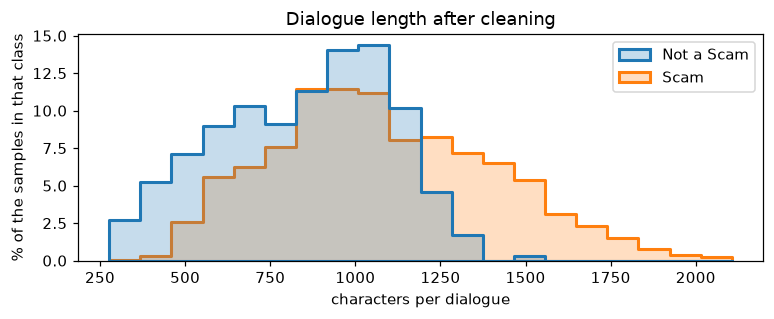

length alone: a call with 1163+ characters is a scam -> balanced accuracy 0.65
length alone: a call with 276+ words is a scam -> balanced accuracy 0.62
length alone: a call with 8+ turns is a scam -> balanced accuracy 0.57


,median characters,median words,median turns
type,,,
fake_authority,993.0,218.0,10.0
investment,1036.5,243.0,12.0
lottery,1129.0,250.0,11.0
normal,878.0,210.0,13.0
phishing_otp,949.5,225.5,10.0
romance,1132.0,271.5,12.0


In [8]:
from sklearn.metrics import roc_curve

df["characters"] = df["text"].str.len()
df["words"] = df["text"].map(lambda text: len(thai_words(text)))
df["turn_count"] = df["speaker_turns"].map(len)

fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(
    data=df, x="characters", hue="scam_class", hue_order=list(CLASS_COLORS), palette=CLASS_COLORS,
    bins=20, stat="percent", common_norm=False, element="step", alpha=0.25, linewidth=2, ax=ax,
)  # fmt: skip
ax.set(
    title="Dialogue length after cleaning",
    xlabel="characters per dialogue",
    ylabel="% of the samples in that class",
)
ax.get_legend().set_title(None)
plt.tight_layout()
save_chart("step03_length_histogram")


def best_cutoff(values: pd.Series, is_scam: np.ndarray) -> tuple[int, float]:
    """Find the length cut-off that best splits scam from normal calls, by balanced accuracy."""
    fpr, tpr, thresholds = roc_curve(is_scam, values)
    best = np.argmax(tpr - fpr)
    return int(thresholds[best]), float((tpr[best] + 1 - fpr[best]) / 2)


is_scam = df["scam_class"].eq("Scam").to_numpy()
for column, unit in {"characters": "characters", "words": "words", "turn_count": "turns"}.items():
    cut, score = best_cutoff(df[column], is_scam)
    print(f"length alone: a call with {cut}+ {unit} is a scam -> balanced accuracy {score:.2f}")

call_type = df["scam_type"].where(df["scam_class"].eq("Scam"), "normal").replace("", "scam_other")
save_table(
    df.groupby(call_type)[["characters", "words", "turn_count"]]
    .median()
    .rename_axis("type")
    .rename(
        columns={
            "characters": "median characters",
            "words": "median words",
            "turn_count": "median turns",
        }
    ),
    "step03_length_by_type",
)

## Step 4. Label mapping

Every scam call must name one of the 5 spec types; another name stops the notebook. Exact
duplicate texts are removed; copies with different labels are all dropped.

dropped 0 exact duplicates with the same label, 2199 samples left


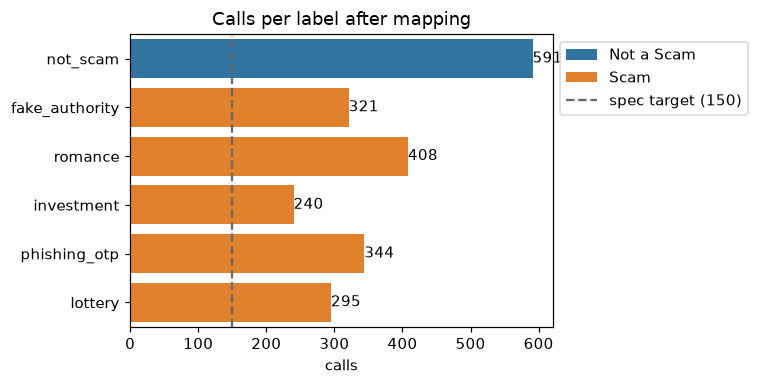

,samples,spec target,short by
stratum,,,
not_scam,591,150,0
fake_authority,321,150,0
romance,408,150,0
investment,240,150,0
phishing_otp,344,150,0
lottery,295,150,0


In [9]:
SCAM_TYPES = ("fake_authority", "romance", "investment", "phishing_otp", "lottery")
SPEC_TARGET = 150  # calls per label the spec asks for

df["label_scam"] = df["scam_class"].eq("Scam")

unknown = sorted(set(df.loc[df["label_scam"], "scam_type"]) - set(SCAM_TYPES))
if unknown:
    raise ValueError(f"scam types outside {SCAM_TYPES}: {unknown}")

df["label_type"] = [
    scam_type if is_scam else None
    for scam_type, is_scam in zip(df["scam_type"], df["label_scam"], strict=True)
]
# Step 6 stratifies on this, so each split keeps about the same share of every type.
df["stratum"] = np.where(df["label_scam"], df["label_type"], "not_scam")

conflicting = df.groupby("text")["stratum"].transform("nunique") > 1
if conflicting.any():
    print(f"\ndropped {conflicting.sum()} samples: same text, different labels")
    print(
        df[conflicting]
        .groupby("text")["scam_type"]
        .agg(lambda types: " | ".join(sorted(set(types))))
        .to_string(index=False)
    )
before = len(df)
df = df[~conflicting].drop_duplicates(subset="text").reset_index(drop=True)
print(
    f"dropped {before - conflicting.sum() - len(df)} exact duplicates with the same label, {len(df)} samples left"
)

counts = df["stratum"].value_counts().rename("samples").to_frame()
counts["spec target"] = SPEC_TARGET
counts["short by"] = (counts["spec target"] - counts["samples"]).clip(lower=0)
counts = (
    counts.reindex(["not_scam", *SCAM_TYPES])
    .fillna({"samples": 0, "spec target": SPEC_TARGET, "short by": SPEC_TARGET})
    .astype(int)
)

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.barplot(
    x=counts["samples"], y=counts.index, palette=CLASS_COLORS, ax=ax,
    hue=["Not a Scam" if label == "not_scam" else "Scam" for label in counts.index],
)  # fmt: skip
for container in ax.containers:
    ax.bar_label(container)
ax.axvline(SPEC_TARGET, color="dimgray", linestyle="--", label=f"spec target ({SPEC_TARGET})")
ax.set(title="Calls per label after mapping", xlabel="calls", ylabel="")
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
save_chart("step04_samples_per_label")

save_table(counts, "step04_samples_per_label_table")
counts.style.bar(subset=["short by"], color="#f5c2ad", vmin=0, vmax=SPEC_TARGET)

## Step 4b. Class sizes

Every usable call is kept, so scam calls outnumber normal calls; part B uses class weights
instead of downsampling. `SKIP_TYPES` leaves a type out. Step 6 stratifies on `stratum` (the
type, or `not_scam`).

In [10]:
SKIP_TYPES: set[str] = set()  # scam types left out, e.g. {"romance"}
OUTCOMES = ("scammed", "safe")

scams = df["label_scam"]
outcome = df["scam_outcome"].where(df["scam_outcome"].isin(OUTCOMES), "none")
available = pd.crosstab(df.loc[scams, "label_type"], outcome[scams]).reindex(
    columns=[*OUTCOMES, "none"], fill_value=0
)
available["skipped"] = available.index.isin(SKIP_TYPES)
print("=== Usable calls per scam type and outcome ===")
print(save_table(available, "step04b_usable_calls").to_string())

skipped = df["label_type"].isin(SKIP_TYPES)
if skipped.any():
    print(f"left out {skipped.sum()} calls of the types in SKIP_TYPES")
df = df[~skipped].reset_index(drop=True)
if not df["label_scam"].any() or df["label_scam"].all():
    raise ValueError("both scam and normal calls are needed: add calls or empty SKIP_TYPES")

classes = df["scam_class"].value_counts()
print(
    f"\n{len(df)} samples kept: "
    + ", ".join(f"{n} {name}" for name, n in classes.items())
    + f" ({classes.max() / classes.min():.1f} to 1, Part B weights the classes)"
)
save_table(
    pd.crosstab(df["label_type"].fillna("normal"), df["scam_outcome"].fillna("-")).rename_axis(
        index="type", columns="scam_outcome"
    ),
    "step04b_type_by_outcome",
)

=== Usable calls per scam type and outcome ===
scam_outcome    scammed  safe  none  skipped
label_type                                  
fake_authority      143   178     0    False
investment          112   128     0    False
lottery             152   143     0    False
phishing_otp        163   181     0    False
romance             208   200     0    False

2199 samples kept: 1608 Scam, 591 Not a Scam (2.7 to 1, Part B weights the classes)


scam_outcome,-,safe,scammed
type,,,
fake_authority,0,178,143
investment,0,128,112
lottery,0,143,152
normal,591,0,0
phishing_otp,0,181,163
romance,0,200,208


## Step 5. Groups: one per scenario

Calls of one scenario are alike, so each scenario is one group and stays in one split.
Otherwise the test score would measure memory of a scenario.

In [11]:
df["group"] = pd.factorize(df["scenario"])[0]
group_sizes = df["group"].value_counts()
print(
    f"{len(df)} samples in {len(group_sizes)} groups, {group_sizes.min()} to {group_sizes.max()} samples each"
)

call_type = df["label_type"].fillna("normal")
per_scenario = (
    df.groupby(
        [call_type.rename("type"), df["scenario"].str.split("/", n=1).str[1].rename("scenario")]
    )
    .size()
    .rename("calls")
    .reset_index()
    .sort_values(["type", "calls"], ascending=[True, False])
)
print("=== Calls in each scenario ===")
print(per_scenario.to_string(index=False))
print()
save_table(
    pd.DataFrame(
        {
            "calls": call_type.value_counts(),
            "scenarios": df.groupby(call_type)["scenario"].nunique(),
            "groups": df.groupby(call_type)["group"].nunique(),
        }
    ).rename_axis("type"),
    "step05_groups_per_type",
)

2199 samples in 792 groups, 1 to 48 samples each
=== Calls in each scenario ===
          type                                                scenario  calls
fake_authority                                   fake_mea_meter_change     16
fake_authority                                          police_warrant     15
fake_authority                                          customs_parcel     14
fake_authority                                             revenue_tax     13
fake_authority                                   vaccine_followup_scam     13
fake_authority                                           court_summons     12
fake_authority                            credit_card_unpaid_statement     12
fake_authority                            fake_deposit_protection_line     12
fake_authority                                        fake_gov_project     12
fake_authority                             fake_land_dept_line_contact     12
fake_authority                                   fake_sec_regi

,calls,scenarios,groups
type,,,
fake_authority,321,95,95
investment,240,80,80
lottery,295,79,79
normal,591,376,376
phishing_otp,344,77,77
romance,408,85,85


## Step 6. Train / valid / test split by scenario (70 / 15 / 15)

`StratifiedGroupKFold` takes test, then valid from the rest, whole scenarios only, with about
the same share of each type and, within it, of existing and Sonnet calls (`split_key`). Counts land close to 70 / 15 / 15. The split is made fresh on
every run.

share of the calls per split: {'train': 0.704, 'valid': 0.148, 'test': 0.148}


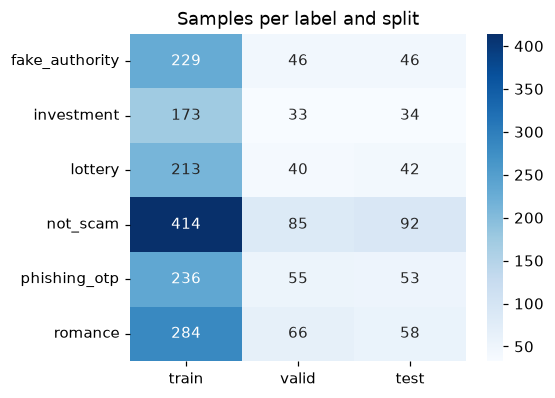

=== Scenarios per label and split ===
split           train  valid  test
stratum                           
fake_authority     68     14    13
investment         57     11    12
lottery            56     12    11
not_scam          268     54    54
phishing_otp       55     11    11
romance            60     13    12

valid scenarios:
  fake_authority (14): airport_found_wallet_courier_fee, court_probation_officer_report_app, credit_card_unpaid_statement, customs_parcel, cyber_police_fake_shop_victim_refund, expressway_mflow_arrears_link, fake_bank_phone_inquiry, flood_relief_recorded_voice_form_fee, hit_and_run_compensation_police, mea_rooftop_solar_buyback_bonus, official_line_loan, police_lost_wallet_found_id_data, pwa_meter_reader_app_install, sso_maternity_benefit_account_mismatch
  investment (11): ai_gold_bot_workshop_package, condo_presale_unit_resale_pool, durian_tree_adoption_fund, forex_ea_robot_monthly_license, home_bag_folding_starter_kit, oil_futures_teacher_trial_class, p

split,train,valid,test
stratum,,,
fake_authority,229,46,46
investment,173,33,34
lottery,213,40,42
not_scam,414,85,92
phishing_otp,236,55,53
romance,284,66,58
total,1549,325,325


In [12]:
from sklearn.model_selection import StratifiedGroupKFold

SPLIT_RATIOS = {"train": 0.70, "valid": 0.15, "test": 0.15}


def take_fold(rows: pd.DataFrame, share: float, seed: int) -> pd.Index:
    """Pick about `share` of the rows, whole groups only, with every stratum in it."""
    splitter = StratifiedGroupKFold(n_splits=round(1 / share), shuffle=True, random_state=seed)
    folds = [held_out for _, held_out in splitter.split(rows, rows["split_key"], rows["group"])]
    every = set(rows["split_key"])
    target = share * len(rows)
    held_out = min(
        folds,
        key=lambda fold: (bool(every - set(rows["split_key"].iloc[fold])), abs(len(fold) - target)),
    )
    return rows.index[held_out]


def scenario_split(frame: pd.DataFrame, ratios: dict[str, float], seed: int) -> pd.Series:
    """Name the split of each row: test first, then valid from the rest."""
    split = pd.Series("train", index=frame.index)
    test = take_fold(frame, ratios["test"], seed)
    split[test] = "test"
    rest = frame.drop(test)
    split[take_fold(rest, ratios["valid"] / (1 - ratios["test"]), seed)] = "valid"
    return split


source = np.where(df["call_id"].str.contains("_sonnet_"), "sonnet", "existing")
df["split_key"] = df["stratum"] + "/" + source
df["split"] = scenario_split(df, SPLIT_RATIOS, SEED)
for column in ("group", "scenario"):
    assert df.groupby(column)["split"].nunique().max() == 1, f"a {column} is in two splits"
missing = {
    name: sorted(set(df["stratum"]) - set(df.loc[df["split"] == name, "stratum"]))
    for name in SPLIT_RATIOS
}
for name, strata in missing.items():
    if strata:
        print(f"{name} has no calls of: {strata}")
print(
    "share of the calls per split:",
    df["split"].value_counts(normalize=True).reindex(list(SPLIT_RATIOS)).round(3).to_dict(),
)

split_counts = pd.crosstab(df["stratum"], df["split"]).reindex(
    columns=list(SPLIT_RATIOS), fill_value=0
)

fig, ax = plt.subplots(figsize=(5.2, 0.42 * len(split_counts) + 1.2))
sns.heatmap(split_counts, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set(title="Samples per label and split", xlabel="", ylabel="")
plt.tight_layout()
save_chart("step06_split_counts")

scenarios = (
    df.groupby(["stratum", "split"])["scenario"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=list(SPLIT_RATIOS), fill_value=0)
)
print("=== Scenarios per label and split ===")
print(save_table(scenarios, "step06_scenarios_per_split").to_string())

for name in ("valid", "test"):
    print(f"\n{name} scenarios:")
    held_out = (
        df[df["split"] == name].groupby("stratum")["scenario"].agg(lambda names: sorted(set(names)))
    )
    for stratum, names in held_out.items():
        print(
            f"  {stratum} ({len(names)}): "
            + ", ".join(scenario.split("/", 1)[1] for scenario in names)
        )

split_counts.loc["total"] = split_counts.sum()
save_table(split_counts, "step06_split_counts_table")

### Split checks

The rules for a fair split: each split has about the same label distribution (stratified) and
the same feature distribution, no closely related calls in two splits (here: one scenario stays
in one split), and a test set that looks like real use (per-turn rows, as the app classifies).
The heatmap shows the label share of each split; the boxplot the words per call in each split.

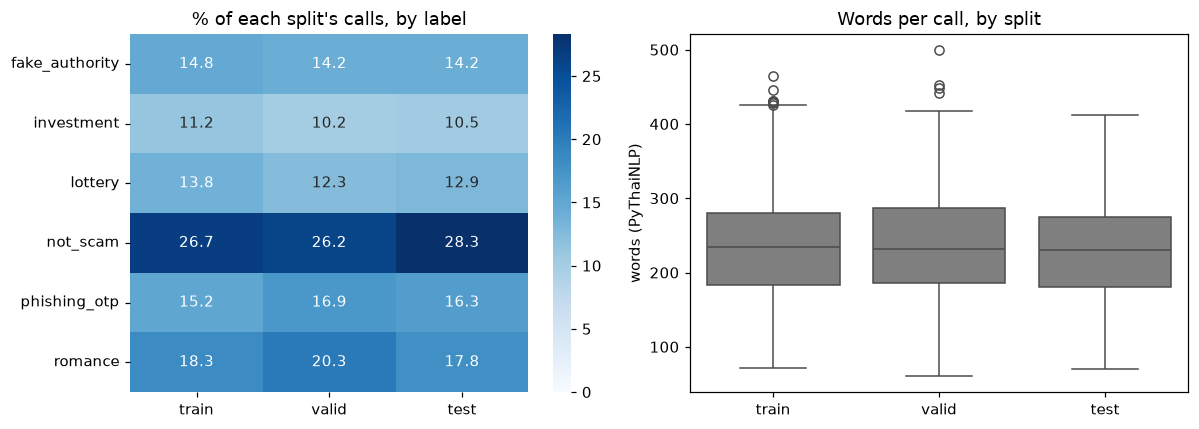

split,train,valid,test
stratum,,,
fake_authority,14.8,14.2,14.2
investment,11.2,10.2,10.5
lottery,13.8,12.3,12.9
not_scam,26.7,26.2,28.3
phishing_otp,15.2,16.9,16.3
romance,18.3,20.3,17.8


In [13]:
label_share = (
    pd.crosstab(df["stratum"], df["split"], normalize="columns")
    .reindex(columns=list(SPLIT_RATIOS))
    .mul(100)
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(label_share, annot=True, fmt=".1f", cmap="Blues", vmin=0, ax=axes[0])
axes[0].set(title="% of each split's calls, by label", xlabel="", ylabel="")
sns.boxplot(data=df, x="split", y="words", order=list(SPLIT_RATIOS), color="tab:gray", ax=axes[1])
axes[1].set(title="Words per call, by split", xlabel="", ylabel="words (PyThaiNLP)")
plt.tight_layout()
save_chart("step06_split_checks")
save_table(label_share.round(1), "step06_label_share_per_split")

## Step 6b. Turn-level samples

Each turn becomes one row. A row of a scam call is scam from `scam_start_turn` on, whoever
speaks; every other row is safe. The spec checks the agent from that turn on, so the label
follows the call, not the speaker.

A row holds the call so far, every line up to the turn, as the app classifies it. Left
truncation cuts the oldest lines to fit `MAX_TOKENS`; `turns_dropped` counts them.

Texts with two labels are dropped; exact copies are kept once.

In [14]:
from functools import cache

from transformers import AutoTokenizer

MODEL_ID = "clicknext/phayathaibert"
MAX_TOKENS = 510  # PhayaThaiBERT's limit; part B trains with this as MAX_LENGTH
SPACE_TOKEN = "<_>"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
USE_SPACE_TOKEN = SPACE_TOKEN in tokenizer.get_vocab()


def to_model_text(text: str) -> str:
    """Write the text the way the tokenizer expects: one space between words, as <_>."""
    text = " ".join(text.split())
    return text.replace(" ", SPACE_TOKEN) if USE_SPACE_TOKEN else text


@cache
def count_tokens(text: str) -> int:
    """Count the model tokens of a text, special tokens included."""
    return len(tokenizer(to_model_text(text), verbose=False)["input_ids"])


print(f"{MODEL_ID}: <_> for spaces: {USE_SPACE_TOKEN}, at most {MAX_TOKENS} tokens")

D:\text_analytics\Callas\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


clicknext/phayathaibert: <_> for spaces: True, at most 510 tokens


In [15]:
def scam_start_of(call):
    """The call's scam start, counted in its cleaned turns. It must be a caller turn."""
    start = None if pd.isna(call.scam_start_clean) else int(call.scam_start_clean)
    if call.label_scam and (start is None or call.speaker_turns[start]["role"] != "caller"):
        raise ValueError(f"{call.call_id}: the scam start is not a caller turn")
    return start


def make_row(call, turn_index: int, first: int, start) -> dict:
    """The row of turn turn_index, holding turns first..turn_index, labelled by the table above."""
    turns = call.speaker_turns
    kept = turns[first : turn_index + 1]
    scam = bool(call.label_scam) and turn_index >= start
    return {
        "call_id": call.call_id,
        "turn_index": turn_index,
        "speaker_turns": kept,
        "text": render(kept),
        "label_scam": scam,
        "label_type": call.label_type if scam else None,
        "scam_outcome": call.scam_outcome if scam else None,
        "scam_outcome_source": call.scam_outcome_source if scam else None,
        # where the scam starts among the row's turns, when the row holds that turn
        "scam_start_turn": start - first
        if start is not None and first <= start <= turn_index
        else None,
        "source": call.source,
        "scam_type": call.scam_type,
        "group": call.group,
        "split": call.split,
        "scenario": call.scenario,
        "turns_dropped": first,  # old lines cut to fit MAX_TOKENS
    }

In [16]:
def call_so_far_rows(call) -> list[dict]:
    """Each row holds every line up to the turn. When that is longer than MAX_TOKENS, the oldest
    lines are cut; the turn's own line always stays."""
    start = scam_start_of(call)
    turns = call.speaker_turns
    rows, first = [], 0
    for turn_index in range(len(turns)):
        # A row only grows from one turn to the next, so the cut only moves forward.
        while (
            first < turn_index and count_tokens(render(turns[first : turn_index + 1])) > MAX_TOKENS
        ):
            first += 1
        rows.append(make_row(call, turn_index, first, start))
    return rows

In [17]:
rows = pd.DataFrame([row for call in df.itertuples() for row in call_so_far_rows(call)])
print(f"{len(rows)} rows from {len(df)} calls")

two_labels = rows.groupby("text")["label_scam"].transform("nunique") > 1
copies = rows.duplicated("text") & ~two_labels
print(f"dropped {two_labels.sum()} rows whose text has two labels and {copies.sum()} exact copies")
rows = rows[~two_labels & ~copies].reset_index(drop=True)
assert rows.groupby("text")["split"].nunique().max() == 1, "a text is in two splits"
last_line = rows["text"].str.rsplit("\n", n=1).str[-1]

label = rows["label_scam"].map({True: "scam", False: "safe"})
print(f"\n{len(rows)} rows: {label.eq('scam').sum()} scam, {label.eq('safe').sum()} safe")
was_cut = rows["turns_dropped"] > 0
print(f"{was_cut.sum()} rows ({was_cut.mean():.1%}) lost old lines to fit {MAX_TOKENS} tokens")
print(
    save_table(
        pd.crosstab(label, rows["split"])
        .reindex(columns=list(SPLIT_RATIOS), fill_value=0)
        .rename_axis(index="label", columns="split"),
        "step06b_rows_per_split",
    ).to_string()
)

# One scam call example_call as its rows: one of 5 turns or more when there is one.
scam_calls = df.loc[df["label_scam"], ["call_id", "speaker_turns"]]
if len(scam_calls):
    long_enough = scam_calls[scam_calls["speaker_turns"].map(len) >= 5]
    example_call = (long_enough if len(long_enough) else scam_calls)["call_id"].iat[0]
    start = df.set_index("call_id").at[example_call, "scam_start_clean"]
    print(f"\n{example_call} as rows (scam_start_turn {start}); 'line' is the row's last line:")
    print(
        rows.loc[
            rows["call_id"] == example_call,
            ["turn_index", "turns_dropped", "label_scam"],
        ]
        .assign(line=last_line[rows["call_id"] == example_call].str.slice(0, 70))
        .to_string(index=False)
    )

23052 rows from 2199 calls
dropped 0 rows whose text has two labels and 1555 exact copies

21497 rows: 7476 scam, 14021 safe
89 rows (0.4%) lost old lines to fit 510 tokens
split  train  valid  test
label                    
safe    9936   2054  2031
scam    5250   1113  1113

fake_authority_00050 as rows (scam_start_turn 0); 'line' is the row's last line:
 turn_index  turns_dropped  label_scam                                                                   line
          0              0        True B: สวัสดีครับ ติดต่อจาก [ORG] ครับ เรียนคุณ [PERSON] ครับ ไม่ต้องตกใจค
          1              0        True A: สวัสดีครับ ภาษีคืนเหรอครับ แล้วมียอดเท่าไหร่หรือมีเรื่องอะไรเพิ่มเต
          2              0        True B: ยอดเงินคืนของท่านอยู่ที่ประมาณ [MONEY]ครับ ทางเราขอแจ้งว่าเงินคืนนี
          3              0        True A: เอ่อ... ขอทราบชื่อผู้แจ้งหรือเลขที่อ้างอิงหน่อยครับ แล้วทำไมถึงต้อง
          4              0        True B: ผมชื่อ [PERSON] จากแผนกบริหารภาษีครับ สำหรับเรื่อ

### Token counts

Tokens per line (by type and role) and per row (safe vs scam), counted as part B counts them.
Scam rows are longer because they come later in the call. The cell also shows rows over the
limit before the cut, and one cut row line by line.

In [18]:
call_of = df.set_index("call_id")
kind_of = call_of["label_type"].where(call_of["label_scam"], "normal")
rows["type"] = rows["call_id"].map(kind_of)
rows["tokens"] = rows["text"].map(count_tokens)

line_tokens = pd.DataFrame(
    [
        {
            "type": kind_of[call_id],
            "role": turn["role"],
            "tokens": count_tokens(f"{turn['speaker']}: {turn['text']}"),
        }
        for call_id, turns in zip(df["call_id"], df["speaker_turns"], strict=True)
        for turn in turns
    ]
)
print("=== Tokens per line ===")
display(
    save_table(
        line_tokens.groupby(["type", "role"])["tokens"]
        .agg(["count", "mean", "std", "median", "max"])
        .round(1),
        "step06b_tokens_per_line",
    )
)
longest = line_tokens["tokens"].max()
print(f"longest line: {longest} tokens, at most {MAX_TOKENS}")
assert longest <= MAX_TOKENS, "a line is longer than part B reads"

print("=== Tokens per row: safe vs scam ===")
display(
    save_table(
        rows.groupby(rows["label_scam"].map({True: "scam", False: "safe"}))["tokens"]
        .agg(rows="size", mean_tokens="mean", max_tokens="max")
        .round(1)
        .rename_axis("label"),
        "step06b_tokens_safe_vs_scam",
    )
)

rows["tokens_before_cut"] = [
    count_tokens(render(call_of.at[call_id, "speaker_turns"][: turn_index + 1]))
    for call_id, turn_index in zip(rows["call_id"], rows["turn_index"], strict=True)
]
by_type = rows.groupby("type")
print("=== Tokens per row, before the cut ===")
display(
    save_table(by_type["tokens_before_cut"].agg(["count", "mean", "std", "median", "max"]).round(1)
    .assign(**{f"% over {MAX_TOKENS}": by_type["tokens_before_cut"].apply(lambda counts: (counts > MAX_TOKENS).mean() * 100).round(1)}), "step06b_tokens_before_cut")
)  # fmt: skip
print("=== Rows that lost old lines ===")
display(
    save_table(
        pd.DataFrame(
            {
                "rows": by_type.size(),
                "lost old lines": by_type["turns_dropped"].apply(lambda counts: (counts > 0).sum()),
                "%": by_type["turns_dropped"]
                .apply(lambda counts: (counts > 0).mean() * 100)
                .round(1),
                "lines cut (mean, when cut)": by_type["turns_dropped"]
                .apply(lambda counts: counts[counts > 0].mean())
                .round(1),
                "lines cut (max)": by_type["turns_dropped"].max(),
            }
        ),
        "step06b_rows_cut",
    )
)
cut_rows = rows[rows["turns_dropped"].between(2, 4)]
if len(cut_rows):
    example = cut_rows.iloc[0]
    turns = call_of.at[example["call_id"], "speaker_turns"][: example["turn_index"] + 1]
    print(f"\n{example['call_id']}, row {example['turn_index']}: {example['tokens_before_cut']} tokens "
          f"before the cut, {example['tokens']} after (at most {MAX_TOKENS})")  # fmt: skip
    for turn_index, turn in enumerate(turns):
        line = f"{turn['speaker']}: {turn['text']}"
        status = (
            "cut    "
            if turn_index < example["turns_dropped"]
            else ("current" if turn_index == example["turn_index"] else "kept   ")
        )
        print(f"  [{turn_index}] {status} {count_tokens(line):4d} tokens | {line[:80]}")

=== Tokens per line ===


count  mean   std  median  max
type           role                                    
fake_authority caller     1617  42.7  17.1    40.0  135
               receiver   1553  23.5   7.4    22.0   61
investment     caller     1273  44.5  16.1    43.0  108
               receiver   1248  23.4   7.3    22.0   59
lottery        caller     1589  46.0  18.6    44.0  109
               receiver   1552  23.6   7.7    22.0   56
normal         caller     3389  31.1   9.9    31.0   67
               receiver   3037  22.1   7.0    21.0   58
phishing_otp   caller     1670  44.1  17.0    40.0  110
               receiver   1611  23.3   6.9    22.0   53
romance        caller     2285  37.5  12.7    36.0   99
               receiver   2228  27.0   7.6    26.0   64

longest line: 135 tokens, at most 510
=== Tokens per row: safe vs scam ===


,rows,mean_tokens,max_tokens
label,,,
safe,14021,146.4,472
scam,7476,273.6,510


=== Tokens per row, before the cut ===


,count,mean,std,median,max,% over 510
type,,,,,,
fake_authority,2870,192.1,111.2,177.0,603,0.7
investment,2299,208.5,116.8,192.0,612,1.1
lottery,2829,210.8,118.1,195.0,651,1.1
normal,6304,176.1,103.3,167.0,472,0.0
phishing_otp,2815,195.5,103.9,182.0,584,0.4
romance,4380,186.3,111.1,173.0,574,0.1


=== Rows that lost old lines ===


,rows,lost old lines,%,"lines cut (mean, when cut)",lines cut (max)
type,,,,,
fake_authority,2870,20,0.7,1.8,4
investment,2299,25,1.1,1.9,3
lottery,2829,30,1.1,1.8,5
normal,6304,0,0.0,NaN,0
phishing_otp,2815,10,0.4,1.5,3
romance,4380,4,0.1,1.5,3



fake_authority_00074, row 12: 566 tokens before the cut, 485 after (at most 510)
  [0] cut       30 tokens | B: สวัสดีค่ะ ติดต่อจาก [ORG] นะคะ เรียนสายคุณ [PERSON] ค่ะ
  [1] cut       16 tokens | A: สวัสดีครับ ผมพูดครับ มีอะไรหรือเปล่าครับ
  [2] cut       38 tokens | B: ขอบคุณค่ะคุณ [PERSON] รบกวนถือสายรอสักครู่นะคะ ทางเราขออนุญาตตรวจสอบข้อมูลในร
  [3] kept      17 tokens | A: ครับ ว่ายังไงครับ มีเรื่องอะไรหรือเปล่าครับ
  [4] kept      72 tokens | B: คือทางเราตรวจสอบพบข้อมูลบัตรเครดิตหมายเลข [CARD_NUMBER] ของคุณ [PERSON] นะคะ 
  [5] kept      30 tokens | A: หือ อะไรนะคร้บ เมื่อกี้ว่ายังไงนะ รบกวนพูดอีกรอบได้ไหมครับ ผมจำไม่ได้ว่าไปถอน
  [6] kept      83 tokens | B: ได้ค่ะคุณ [PERSON] คือทางเราพบข้อมูลบัตรหมายเลข [CARD_NUMBER] วงเงิน [MONEY] 
  [7] kept      36 tokens | A: วันที่ 15 มิถุนายนเหรอครับ... ผมก็นึกไม่ออกเด้ว่าไปถอนตอนไหน มันเป็นเงินจำนวน
  [8] kept      75 tokens | B: ใช่ค่ะคุณ [PERSON] ยอดเงิน [MONEY] ถูกต้องตามระบบเลยค่ะ แต่เอ๊ะ ทางเราแปลกใจม
  [9] kept      30 tokens | A:

## Step 7. Export

Writes `data/processed_balanced/{train,valid,test,dataset}.csv`, one row per turn, utf-8-sig
so Excel shows Thai. Columns follow the record schema in `docs/spec.html`, with list columns
as JSON text, plus `raw_type`, `group`, `call_id`, `scenario`, `scam_outcome`,
`scam_outcome_source`, `turn_index` and `turns_dropped`. Every record is checked against the
schema before writing.

In [19]:
CSV_ENCODING = "utf-8-sig"

RECORD_KEYS = (
    "id", "channel", "text", "audio_path", "speaker_turns", "label_scam", "label_type",
    "entities", "scam_start_turn", "source", "raw_type", "group",
    "call_id", "scam_outcome", "scam_outcome_source", "scenario", "turn_index", "turns_dropped",
)  # fmt: skip


def text_or_none(value):
    """Return the text, or None when it is empty or NaN."""
    return value if isinstance(value, str) and value else None


def to_record(row) -> dict:
    """Build the spec record of one row from step 6b."""
    return {
        "id": f"{row.call_id}_t{row.turn_index:02d}",
        "channel": "call",
        "text": row.text,
        "audio_path": None,
        "speaker_turns": row.speaker_turns,
        "label_scam": bool(row.label_scam),
        "label_type": text_or_none(row.label_type),
        "entities": [],
        "scam_start_turn": None if pd.isna(row.scam_start_turn) else int(row.scam_start_turn),
        "source": row.source,
        "raw_type": row.scam_type,
        "group": int(row.group),
        "call_id": row.call_id,
        "scam_outcome": text_or_none(row.scam_outcome),
        "scam_outcome_source": text_or_none(row.scam_outcome_source),
        "scenario": row.scenario,
        "turn_index": int(row.turn_index),
        "turns_dropped": int(row.turns_dropped),
    }


def check_record(rec: dict, keys: tuple = RECORD_KEYS) -> None:
    """Fail on a record that breaks the spec schema."""
    assert tuple(rec) == keys, f"{rec.get('id')}: wrong keys"
    assert rec["channel"] in ("call", "message")
    assert rec["text"].strip(), f"{rec['id']}: empty text"
    assert isinstance(rec["label_scam"], bool)
    assert rec["label_type"] is None or rec["label_type"] in SCAM_TYPES, (
        f"{rec['id']}: bad label_type"
    )
    assert rec["label_scam"] or rec["label_type"] is None, f"{rec['id']}: type on a safe row"
    assert rec["label_scam"] or rec["scam_outcome"] is None, f"{rec['id']}: outcome on a safe row"
    assert all(turn["speaker"] and turn["text"] for turn in rec["speaker_turns"])


LIST_COLUMNS = ("speaker_turns", "entities")  # stored as JSON text inside the csv


def write_records(path: Path, records: list[dict], keys: tuple = RECORD_KEYS) -> None:
    """Write records to a csv, with the list columns as JSON text."""
    frame = pd.DataFrame(records, columns=list(keys))
    frame["scam_start_turn"] = frame["scam_start_turn"].astype("Int64")
    for col in LIST_COLUMNS:
        frame[col] = frame[col].map(lambda value: json.dumps(value, ensure_ascii=False))
    frame.to_csv(path, index=False, encoding=CSV_ENCODING)


records = {name: [] for name in SPLIT_RATIOS}
for row in rows.itertuples():
    rec = to_record(row)
    check_record(rec)
    records[row.split].append(rec)
PROCESSED.mkdir(parents=True, exist_ok=True)
write_records(
    PROCESSED / "dataset.csv", [record for name in SPLIT_RATIOS for record in records[name]]
)
for name in SPLIT_RATIOS:
    path = PROCESSED / f"{name}.csv"
    write_records(path, records[name])
    print(f"wrote {len(records[name]):5d} rows to {path.relative_to(ROOT)}")

wrote 15186 rows to data\processed_balanced\train.csv
wrote  3167 rows to data\processed_balanced\valid.csv
wrote  3144 rows to data\processed_balanced\test.csv


# Part B. Modeling and evaluation

- Gate labels: `not_scam`, `scam`, on every row.
- Type labels: the spec types with rows in train (all but `SKIP_TYPES`), on scam rows only.
  Each must also have rows in valid and in test.

In [20]:
def read_records(path: Path) -> pd.DataFrame:
    """Read a split csv that part A wrote."""
    frame = pd.read_csv(path, encoding=CSV_ENCODING)
    for col in LIST_COLUMNS:
        frame[col] = frame[col].map(json.loads)
    return frame.astype(object).where(frame.notna(), None).astype({"label_scam": bool})


data = {name: read_records(PROCESSED / f"{name}.csv") for name in SPLIT_RATIOS}

GATE_LABELS = ["not_scam", "scam"]
for frame in data.values():
    frame["gate"] = frame["label_scam"].astype(int)

type_counts = (
    pd.DataFrame({name: frame["label_type"].value_counts() for name, frame in data.items()})
    .reindex(SCAM_TYPES)
    .fillna(0)
    .astype(int)
)
type_counts["total"] = type_counts.sum(axis=1)
TYPE_LABELS = [scam_type for scam_type in SCAM_TYPES if type_counts.at[scam_type, "train"] > 0]
assert len(TYPE_LABELS) >= 2, "the type model needs at least 2 scam types"
assert (type_counts.loc[TYPE_LABELS, ["valid", "test"]] > 0).to_numpy().all(), (
    "a scam type has no rows in valid or test"
)

typed = {name: frame[frame["label_type"].isin(TYPE_LABELS)].copy() for name, frame in data.items()}
for frame in typed.values():
    frame["type"] = frame["label_type"].map(TYPE_LABELS.index)

print("type model trains on:", TYPE_LABELS)
save_table(type_counts, "partb_type_counts")
type_counts.style.background_gradient(cmap="Blues", axis=None)

type model trains on: ['fake_authority', 'romance', 'investment', 'phishing_otp', 'lottery']


,train,valid,test,total
label_type,,,,
fake_authority,1100,218,212,1530
romance,1329,287,263,1879
investment,797,181,201,1179
phishing_otp,1018,256,255,1529
lottery,1006,171,182,1359


## Step 8. Baseline: TF-IDF bag-of-n-grams + logistic regression

Thai has no spaces between words, so `thai_words` does word segmentation (PyThaiNLP `newmm`,
dictionary-based maximal matching) first; placeholders stay one word and punctuation is
dropped. TF-IDF weights unigrams and bigrams (sublinear term frequency), and
`class_weight="balanced"` stops the model from always answering the bigger class.

`score` evaluates every model the same way on test: sklearn's `classification_report`
(precision, recall and F1 per class, macro and weighted averages) and a 95% bootstrap interval
for macro-F1, redrawn call by call because the rows of one call are alike. `plot_confusion_matrices` draws the models side by side, each normalized by the
actual class (each row sums to 1, so the diagonal is each class's recall).

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.pipeline import make_pipeline

N_BOOTSTRAP = 2000
results: list[dict] = []
predictions: dict[tuple[str, str], tuple[np.ndarray, np.ndarray]] = {}


def score(task: str, model: str, y_true, y_pred, label_names: list[str], calls) -> None:
    """Print the classification report and a macro-F1 interval, and keep the scores."""
    ids = list(range(len(label_names)))
    print(f"=== {task} / {model} ===")
    print(
        classification_report(
            y_true, y_pred, labels=ids, target_names=label_names, digits=3, zero_division=0
        )
    )
    report = classification_report(
        y_true, y_pred, labels=ids, target_names=label_names, output_dict=True, zero_division=0
    )
    ci_low, ci_high = bootstrap_f1(y_true, y_pred, calls, ids)
    print(f"macro-F1 95% bootstrap interval: {ci_low:.3f} to {ci_high:.3f}\n")
    per_class = (
        pd.DataFrame(report)
        .T.loc[label_names, ["precision", "recall", "f1-score", "support"]]
        .rename(columns={"f1-score": "f1"})
        .astype({"support": int})
    )
    predictions[(task, model)] = (np.asarray(y_true), np.asarray(y_pred))
    results.append(
        {
            "task": task,
            "model": model,
            "precision": round(float(report["macro avg"]["precision"]), 4),
            "recall": round(float(report["macro avg"]["recall"]), 4),
            "f1": round(float(report["macro avg"]["f1-score"]), 4),
            "f1_ci_low": round(ci_low, 4),
            "f1_ci_high": round(ci_high, 4),
            "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "n_test": int(len(y_true)),
            "per_class": per_class.round(4).to_dict(orient="index"),
        }
    )


def bootstrap_f1(y_true, y_pred, calls, ids: list[int]) -> tuple[float, float]:
    """Return the 95% interval of macro-F1 over test sets redrawn call by call."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rows_of_call = list(pd.Series(np.asarray(calls)).groupby(np.asarray(calls)).indices.values())
    rng = np.random.default_rng(SEED)
    f1s = []
    for _ in range(N_BOOTSTRAP):
        drawn = rng.integers(len(rows_of_call), size=len(rows_of_call))
        rows = np.concatenate([rows_of_call[i] for i in drawn])
        f1s.append(
            f1_score(y_true[rows], y_pred[rows], labels=ids, average="macro", zero_division=0)
        )
    low, high = np.percentile(f1s, [2.5, 97.5])
    return float(low), float(high)


def plot_confusion_matrices(task: str, label_names: list[str], name: str) -> None:
    """Draw the confusion matrix of every model scored on `task`, normalized by the actual class."""
    models = [model for model in MODEL_COLORS if (task, model) in predictions]
    fig, axes = plt.subplots(
        1, len(models), figsize=(4.5 * len(models), 3.5 + 0.4 * len(label_names))
    )
    for ax, model in zip(np.atleast_1d(axes), models, strict=True):
        y_true, y_pred = predictions[(task, model)]
        ConfusionMatrixDisplay.from_predictions(
            y_true,
            y_pred,
            labels=list(range(len(label_names))),
            display_labels=label_names,
            ax=ax,
            cmap="Blues",
            normalize="true",
            values_format=".2f",
            colorbar=False,
        )
        ax.set_title(model)
        if len(label_names) > 2:
            ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    fig.suptitle(f"{task}: confusion matrices normalized by actual class, test set")
    plt.tight_layout()
    save_chart(name)


def make_baseline():
    """Build the TF-IDF (Thai words and word pairs) + logistic regression pipeline."""
    return make_pipeline(
        TfidfVectorizer(
            tokenizer=thai_words,
            token_pattern=None,
            lowercase=False,
            ngram_range=(1, 2),
            sublinear_tf=True,
            min_df=2,
        ),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    )


gate_baseline = make_baseline().fit(data["train"]["text"], data["train"]["gate"])
gate_baseline_test_pred = gate_baseline.predict(data["test"]["text"])
score(
    "scam_gate",
    "tfidf_logreg",
    data["test"]["gate"],
    gate_baseline_test_pred,
    GATE_LABELS,
    data["test"]["call_id"],
)

type_baseline = make_baseline().fit(typed["train"]["text"], typed["train"]["type"])
score(
    "scam_type",
    "tfidf_logreg",
    typed["test"]["type"],
    type_baseline.predict(typed["test"]["text"]),
    TYPE_LABELS,
    typed["test"]["call_id"],
)

=== scam_gate / tfidf_logreg ===
              precision    recall  f1-score   support

    not_scam      0.949     0.934     0.941      2031
        scam      0.883     0.907     0.895      1113

    accuracy                          0.925      3144
   macro avg      0.916     0.921     0.918      3144
weighted avg      0.925     0.925     0.925      3144

macro-F1 95% bootstrap interval: 0.901 to 0.934

=== scam_type / tfidf_logreg ===
                precision    recall  f1-score   support

fake_authority      0.770     0.759     0.765       212
       romance      0.977     0.981     0.979       263
    investment      0.879     0.871     0.875       201
  phishing_otp      0.825     0.867     0.845       255
       lottery      0.994     0.945     0.969       182

      accuracy                          0.887      1113
     macro avg      0.889     0.885     0.887      1113
  weighted avg      0.888     0.887     0.887      1113

macro-F1 95% bootstrap interval: 0.839 to 0.927



### Trivial baselines: majority class and random

Any model has to beat a model that knows nothing. `DummyClassifier` gives two: always the most
common class (`majority`) and a uniform random class (`random`). Safe rows outnumber scam rows, so
`majority` reaches a high accuracy and a macro-F1 below 0.5, which is why the reports
use macro averages and not accuracy. The confusion matrices put both baselines next to the TF-IDF model; step 13 adds PhayaThaiBERT.

=== scam_gate / majority ===
              precision    recall  f1-score   support

    not_scam      0.646     1.000     0.785      2031
        scam      0.000     0.000     0.000      1113

    accuracy                          0.646      3144
   macro avg      0.323     0.500     0.392      3144
weighted avg      0.417     0.646     0.507      3144

macro-F1 95% bootstrap interval: 0.380 to 0.405

=== scam_type / majority ===
                precision    recall  f1-score   support

fake_authority      0.000     0.000     0.000       212
       romance      0.236     1.000     0.382       263
    investment      0.000     0.000     0.000       201
  phishing_otp      0.000     0.000     0.000       255
       lottery      0.000     0.000     0.000       182

      accuracy                          0.236      1113
     macro avg      0.047     0.200     0.076      1113
  weighted avg      0.056     0.236     0.090      1113

macro-F1 95% bootstrap interval: 0.061 to 0.092

=== scam_g

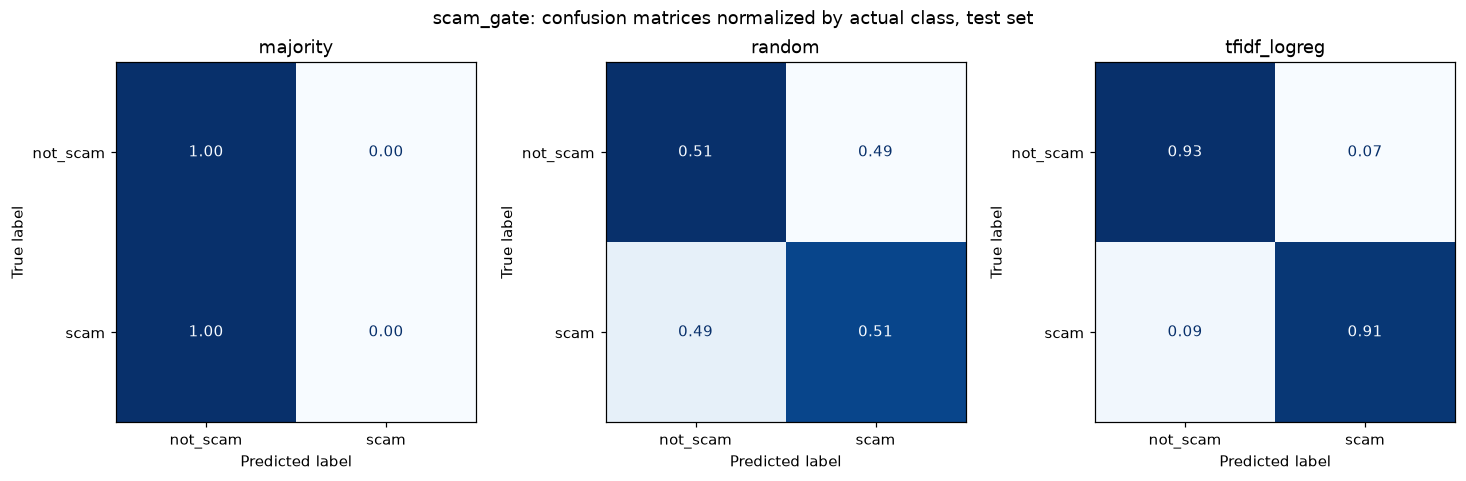

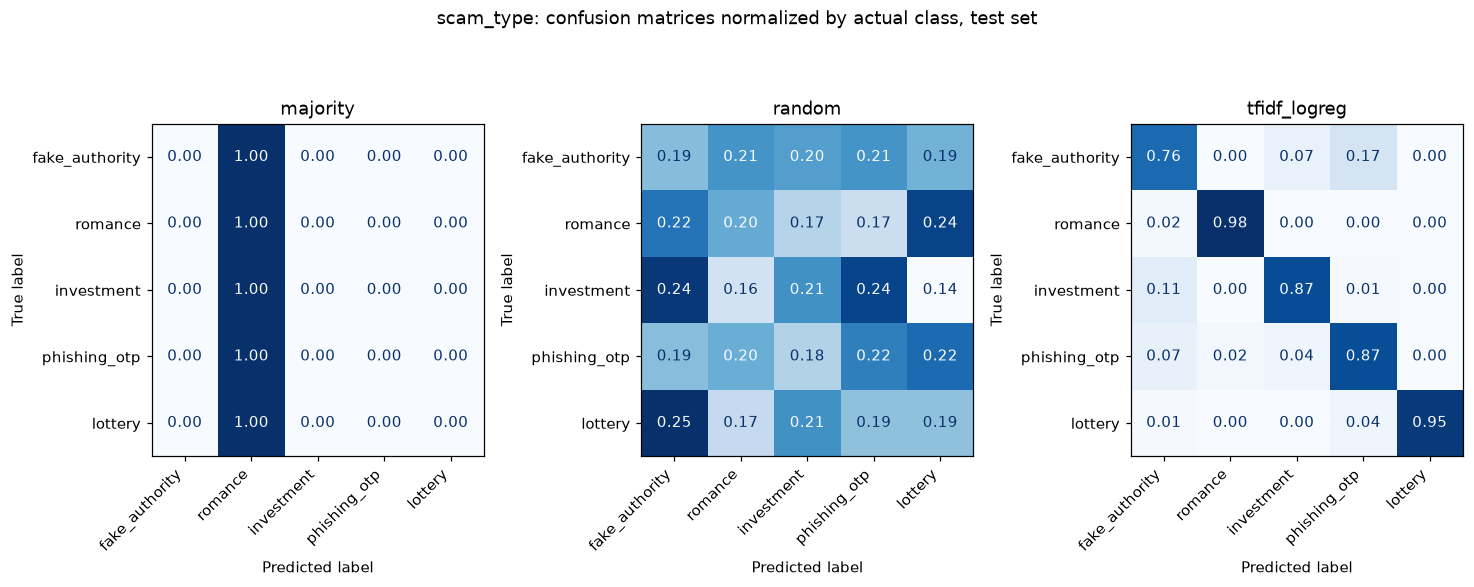

In [22]:
from sklearn.dummy import DummyClassifier

for model, strategy in (("majority", "most_frequent"), ("random", "uniform")):
    dummy = DummyClassifier(strategy=strategy, random_state=SEED)
    dummy.fit(data["train"]["text"], data["train"]["gate"])
    score(
        "scam_gate", model, data["test"]["gate"], dummy.predict(data["test"]["text"]), GATE_LABELS,
        data["test"]["call_id"],
    )  # fmt: skip
    dummy.fit(typed["train"]["text"], typed["train"]["type"])
    score(
        "scam_type",
        model,
        typed["test"]["type"],
        dummy.predict(typed["test"]["text"]),
        TYPE_LABELS,
        typed["test"]["call_id"],
    )

plot_confusion_matrices("scam_gate", GATE_LABELS, "step08_confusion_scam_gate")
plot_confusion_matrices("scam_type", TYPE_LABELS, "step08_confusion_scam_type")

### Ablation by speaker: which speaker does the gate rely on?

The baseline on the full row, the caller's turns only and the receiver's turns only, scored
on valid. If the receiver alone scores close to the full row, the gate learned how the
receiver reacts rather than what the caller does.

=== Gate baseline on full dialogue, valid set ===
              precision    recall  f1-score   support

    not_scam      0.957     0.924     0.940      2054
        scam      0.868     0.924     0.895      1113

    accuracy                          0.924      3167
   macro avg      0.913     0.924     0.918      3167
weighted avg      0.926     0.924     0.924      3167

=== Gate baseline on caller turns only, valid set ===
              precision    recall  f1-score   support

    not_scam      0.954     0.907     0.930      2054
        scam      0.843     0.919     0.880      1113

    accuracy                          0.912      3167
   macro avg      0.899     0.913     0.905      3167
weighted avg      0.915     0.912     0.912      3167

=== Gate baseline on receiver turns only, valid set ===
              precision    recall  f1-score   support

    not_scam      0.886     0.836     0.861      2054
        scam      0.727     0.802     0.763      1113

    accuracy          

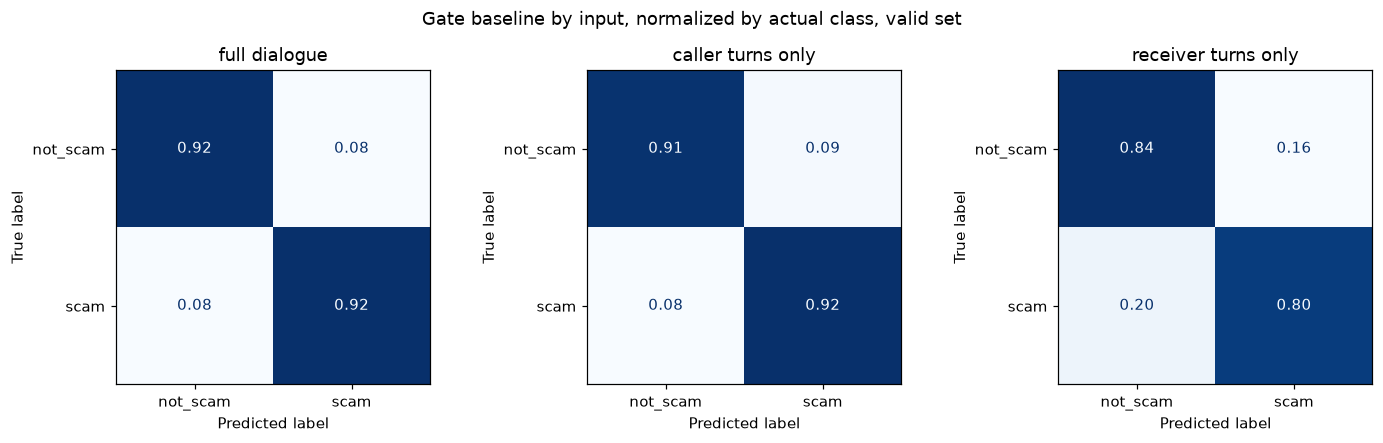

,valid macro-F1
full dialogue,0.918
caller turns only,0.905
receiver turns only,0.812


In [23]:
def turns_of(frame: pd.DataFrame, role: str) -> pd.Series:
    """Join the turns one speaker says in each row."""
    return frame["speaker_turns"].map(
        lambda turns: " ".join(turn["text"] for turn in turns if turn["role"] == role)
    )


gate_inputs = {
    "full dialogue": lambda frame: frame["text"],
    "caller turns only": lambda frame: turns_of(frame, "caller"),
    "receiver turns only": lambda frame: turns_of(frame, "receiver"),
}
speaker_pred = {}
for name, get_text in gate_inputs.items():
    model = make_baseline().fit(get_text(data["train"]), data["train"]["gate"])
    speaker_pred[name] = model.predict(get_text(data["valid"]))
    print(f"=== Gate baseline on {name}, valid set ===")
    print(
        classification_report(
            data["valid"]["gate"], speaker_pred[name], target_names=GATE_LABELS, digits=3
        )
    )

fig, axes = plt.subplots(1, len(speaker_pred), figsize=(13, 4))
for ax, (name, y_pred) in zip(axes, speaker_pred.items(), strict=True):
    ConfusionMatrixDisplay.from_predictions(
        data["valid"]["gate"],
        y_pred,
        display_labels=GATE_LABELS,
        ax=ax,
        cmap="Blues",
        normalize="true",
        values_format=".2f",
        colorbar=False,
    )
    ax.set_title(name)
fig.suptitle("Gate baseline by input, normalized by actual class, valid set")
plt.tight_layout()
save_chart("step08_gate_by_speaker")

speaker_f1 = pd.Series(
    {
        name: f1_score(data["valid"]["gate"], y_pred, average="macro")
        for name, y_pred in speaker_pred.items()
    },
    name="valid macro-F1",
)
save_table(speaker_f1.round(3).to_frame(), "step08_gate_by_speaker_table")

## Step 9. Subword tokenization

PhayaThaiBERT uses SentencePiece subword tokenization (the step 6b tokenizer), with spaces
written as `<_>`. Part A already cut every row to `MAX_LENGTH` tokens.

device: NVIDIA GeForce RTX 5070 Ti
space token in use: True
tokens per row: {'count': 21497, 'mean': 191, 'std': 110, 'min': 12, '25%': 100, '50%': 178, '75%': 269, 'max': 510}


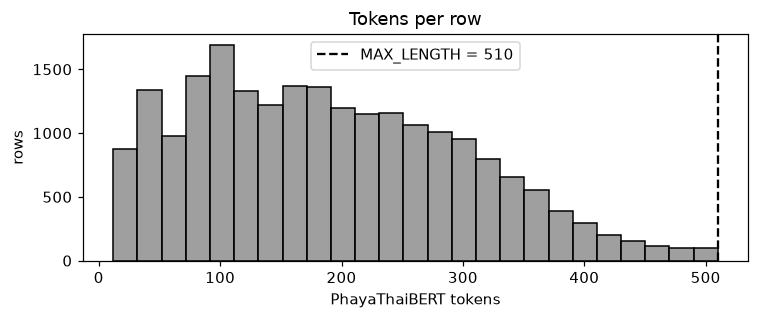

['▁', 'B', ':', '<_>', '▁', 'สวัสดีครับ', '<_>', '▁', 'ติดต่อ', 'จาก', '<_>', '▁[', 'ORG', ']', '<_>', '▁', 'ครับ', '<_>', '▁', 'เรียน', 'คุณ', '<_>', '▁[', 'PER']


In [24]:
import torch

MAX_LENGTH = MAX_TOKENS  # tokenizer, to_model_text and count_tokens come from step 6b

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(
    "device:", torch.cuda.get_device_name(0) if device == "cuda" else "cpu (training will be slow)"
)

all_rows = pd.concat(data.values(), ignore_index=True)
all_rows["tokens"] = all_rows["text"].map(count_tokens)
print("space token in use:", USE_SPACE_TOKEN)
print("tokens per row:", all_rows["tokens"].describe().round(0).astype(int).to_dict())

fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(all_rows["tokens"], bins=25, color="tab:gray", ax=ax)
ax.axvline(MAX_LENGTH, color="black", linestyle="--", label=f"MAX_LENGTH = {MAX_LENGTH}")
ax.set(title="Tokens per row", xlabel="PhayaThaiBERT tokens", ylabel="rows")
ax.legend()
plt.tight_layout()
save_chart("step09_tokens_per_row")

print(tokenizer.tokenize(to_model_text(data["train"]["text"].iat[0])[:60]))

## Step 10. Transfer learning: fine-tune the gate

`fine_tune` fine-tunes the pretrained encoder for sequence classification with class-weighted
cross-entropy. It evaluates on valid `EVALS_PER_EPOCH` times an epoch, stops after `PATIENCE`
evaluations without a better score and keeps the best one (`GATE_EPOCHS` and `TYPE_EPOCHS` are
only upper limits). `BEST_BY` sets the score:

- gate: validation loss, a proper scoring rule. It falls only when the predicted probabilities
  improve, and `GATE_MIN_CONFIDENCE` relies on those probabilities.
- type: validation macro-F1. Its valid loss rose from the first epoch on while F1 still rose,
  and the type model only names the type. It also learns at a third of the gate's rate
  (`LEARNING_RATES`), since it overfit after one epoch.

Each call gives about 9 rows that repeat its earlier lines, so one epoch shows each spoken line
about 5 times. Train loss falling while valid loss rises means overfitting.

`RETRAIN = False` loads the saved models instead of training them.

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1163.39it/s]


Step,Training Loss,Validation Loss,Macro F1,Accuracy
475,0.290297,0.150296,0.946196,0.951058
950,0.127754,0.284918,0.940582,0.946953
1425,0.062636,0.242555,0.942523,0.947269


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.25s/it]


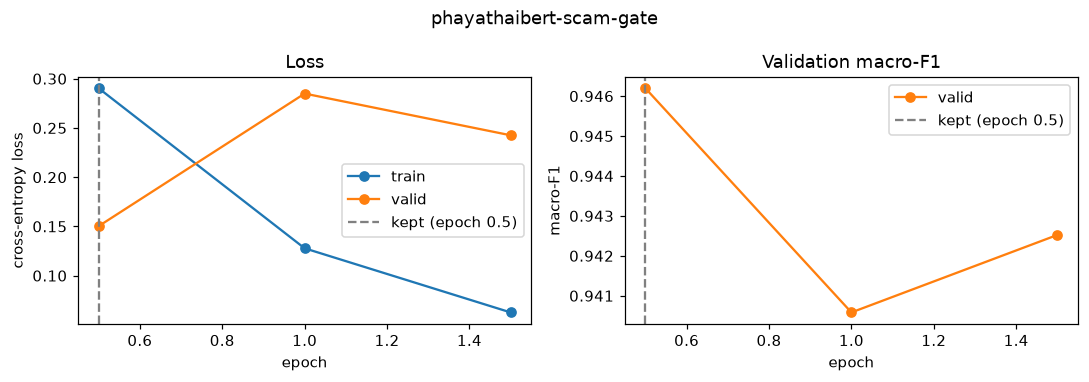

stopped at epoch 1.5 of 4, best eval_loss 0.150


In [25]:
import math
from dataclasses import dataclass

from scipy.special import softmax
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    PreTrainedTokenizerBase,
    PrinterCallback,
    Trainer,
    TrainingArguments,
)
from transformers import logging as hf_logging

RETRAIN = True
MODELS = ROOT / "models"
CHECKPOINTS = ROOT / "checkpoints"
LEARNING_RATES = {"gate": 3e-5, "type": 1e-5}  # the type model overfit after one epoch at 3e-5
BEST_BY = {"gate": "eval_loss", "type": "eval_macro_f1"}  # the valid score that picks the model
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 128
GATE_EPOCHS = 4  # upper limits: early stopping usually ends training sooner
TYPE_EPOCHS = 4
EVALS_PER_EPOCH = 2
PATIENCE = 2  # evaluations without a better valid score before training stops


@dataclass(frozen=True)
class Backbone:
    """A pretrained encoder, how its rows are written, and how it trains."""

    model_id: str
    tokenizer: PreTrainedTokenizerBase
    max_length: int
    space_token: str | None
    learning_rates: dict[str, float]  # by label column: "gate", "type"
    batch_size: int = BATCH_SIZE
    eval_batch_size: int = EVAL_BATCH_SIZE
    accumulation_steps: int = 1
    gradient_checkpointing: bool = False
    lowercase: bool = False  # an uncased vocabulary

    def encode(self, texts):
        """Tokenize rows with one space between words, written as space_token when set."""
        texts = [" ".join(text.split()) for text in texts]
        if self.lowercase:
            texts = [text.lower() for text in texts]
        if self.space_token:
            texts = [text.replace(" ", self.space_token) for text in texts]
        return self.tokenizer(texts, truncation=True, max_length=self.max_length)


PHAYATHAIBERT = Backbone(
    MODEL_ID, tokenizer, MAX_LENGTH, SPACE_TOKEN if USE_SPACE_TOKEN else None, LEARNING_RATES
)


class TextDataset(Dataset):
    """Tokenized texts and their label ids, for the Trainer."""

    def __init__(self, texts, labels, backbone: Backbone = PHAYATHAIBERT):
        self.encodings = backbone.encode(texts)
        self.labels = [int(label) for label in labels]

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, i: int) -> dict:
        item = {key: values[i] for key, values in self.encodings.items()}
        item["labels"] = self.labels[i]
        return item


class WeightedTrainer(Trainer):
    """A Trainer whose loss weighs each class by its rarity."""

    def __init__(self, *args, class_weights: torch.Tensor, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits.float()
        loss = torch.nn.functional.cross_entropy(
            logits, labels, weight=self.class_weights.to(logits.device)
        )
        return (loss, outputs) if return_outputs else loss


def valid_metrics(eval_pred) -> dict:
    """Score one epoch on valid: macro-F1 and accuracy."""
    y_pred = eval_pred.predictions.argmax(axis=-1)
    f1 = f1_score(eval_pred.label_ids, y_pred, average="macro", zero_division=0)
    return {"macro_f1": f1, "accuracy": accuracy_score(eval_pred.label_ids, y_pred)}


def plot_history(trainer: Trainer, name: str, best_by: str) -> None:
    """Draw the learning curves: loss and valid macro-F1 per evaluation, with the kept one."""
    log = pd.DataFrame(trainer.state.log_history)
    train = log.dropna(subset=["loss"]).set_index("epoch") if "loss" in log else pd.DataFrame()
    valid = log.dropna(subset=["eval_macro_f1"]).set_index("epoch")
    best = valid[best_by].idxmin() if best_by.endswith("loss") else valid[best_by].idxmax()

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    if len(train):
        axes[0].plot(train.index, train["loss"], marker="o", label="train")
    axes[0].plot(valid.index, valid["eval_loss"], marker="o", label="valid")
    axes[1].plot(valid.index, valid["eval_macro_f1"], marker="o", color="tab:orange", label="valid")
    for ax in axes:
        ax.axvline(best, color="gray", linestyle="--", label=f"kept (epoch {best:.1f})")
        ax.set_xlabel("epoch")
        ax.legend()
    axes[0].set(title="Loss", ylabel="cross-entropy loss")
    axes[1].set(title="Validation macro-F1", ylabel="macro-F1")
    fig.suptitle(name)
    plt.tight_layout()
    save_chart(f"{name}_history")


def fine_tune(
    name: str,
    train: pd.DataFrame,
    valid: pd.DataFrame,
    label_col: str,
    label_names: list[str],
    epochs: int,
    show: bool = True,
    backbone: Backbone = PHAYATHAIBERT,
) -> Trainer:
    """Fine-tune the encoder on train, stop early and keep the best evaluation by BEST_BY."""
    if not RETRAIN:
        return load_saved(MODELS / name, backbone)
    weights = compute_class_weight(
        "balanced", classes=np.arange(len(label_names)), y=train[label_col]
    )
    steps_per_epoch = math.ceil(len(train) / (backbone.batch_size * backbone.accumulation_steps))
    eval_steps = max(1, steps_per_epoch // EVALS_PER_EPOCH)
    trainer = WeightedTrainer(
        model=new_classifier(label_names, backbone.model_id),
        args=training_args(name, epochs, show, backbone, label_col, eval_steps),
        train_dataset=TextDataset(train["text"], train[label_col], backbone),
        eval_dataset=TextDataset(valid["text"], valid[label_col], backbone),
        data_collator=DataCollatorWithPadding(backbone.tokenizer),
        compute_metrics=valid_metrics,
        class_weights=torch.tensor(weights, dtype=torch.float),
        callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
    )
    if not show:
        trainer.remove_callback(PrinterCallback)
    trainer.train()
    if show:
        plot_history(trainer, name, BEST_BY[label_col])
        print(
            f"stopped at epoch {trainer.state.epoch:.1f} of {epochs}, "
            f"best {BEST_BY[label_col]} {trainer.state.best_metric:.3f}"
        )
    return trainer


def load_saved(model_dir: Path, backbone: Backbone = PHAYATHAIBERT) -> Trainer:
    """Load a model that `save` wrote into a Trainer used only to predict."""
    args = TrainingArguments(
        output_dir=str(CHECKPOINTS / "predict"),
        per_device_eval_batch_size=backbone.eval_batch_size,
        fp16=device == "cuda",
        report_to="none",
    )
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    return Trainer(
        model=model, args=args, data_collator=DataCollatorWithPadding(backbone.tokenizer)
    )


def new_classifier(label_names: list[str], model_id: str = MODEL_ID):
    """Load the pretrained encoder with a new classification head for these labels."""
    verbosity = hf_logging.get_verbosity()
    hf_logging.set_verbosity_error()  # hides "lm_head unused, classifier new": both expected
    model = AutoModelForSequenceClassification.from_pretrained(
        model_id,
        num_labels=len(label_names),
        id2label=dict(enumerate(label_names)),
        label2id={name: i for i, name in enumerate(label_names)},
    )
    hf_logging.set_verbosity(verbosity)
    return model


def training_args(
    name: str, epochs: int, show: bool, backbone: Backbone, label_col: str, eval_steps: int
) -> TrainingArguments:
    """Evaluate and save every eval_steps, and load the best evaluation by BEST_BY at the end."""
    return TrainingArguments(
        output_dir=str(CHECKPOINTS / name),
        num_train_epochs=epochs,
        learning_rate=backbone.learning_rates[label_col],
        per_device_train_batch_size=backbone.batch_size,
        gradient_accumulation_steps=backbone.accumulation_steps,
        gradient_checkpointing=backbone.gradient_checkpointing,
        per_device_eval_batch_size=backbone.eval_batch_size,
        warmup_steps=0.1,  # a float is a share of all steps
        weight_decay=0.01,
        eval_strategy="steps",
        eval_steps=eval_steps,
        save_strategy="steps",
        save_steps=eval_steps,
        save_only_model=True,  # no optimizer state: the run is never resumed
        logging_strategy="steps",
        logging_steps=eval_steps,
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model=BEST_BY[label_col],
        fp16=device == "cuda",
        report_to="none",
        disable_tqdm=not show,
        seed=SEED,
    )


def predict_logits(trainer: Trainer, frame: pd.DataFrame, backbone=PHAYATHAIBERT) -> np.ndarray:
    """Return the model's logits for each row; the labels passed in are placeholders."""
    return trainer.predict(TextDataset(frame["text"], [0] * len(frame), backbone)).predictions


def predict_ids(trainer: Trainer, frame: pd.DataFrame, backbone=PHAYATHAIBERT) -> np.ndarray:
    """Return the predicted label id for each row."""
    return predict_logits(trainer, frame, backbone).argmax(axis=-1)


def save(trainer: Trainer, name: str, backbone: Backbone = PHAYATHAIBERT) -> Path:
    """Save the model, the tokenizer and the text preprocessing the model was trained with."""
    path = MODELS / name
    trainer.save_model(str(path))
    backbone.tokenizer.save_pretrained(str(path))
    # The web system (nlp_core/phayathaibert.py) reads these keys to write the live call the
    # same way, and refuses a model saved without them.
    preprocessing = {
        "input_format": "one turn per line, each line '<speaker letter>: <text>'",
        "row_text": "call_so_far",
        "speaker_letters": {
            turn["role"]: turn["speaker"]
            for turns in data["train"]["speaker_turns"]
            for turn in turns
        },
        "masked_labels": list(MASKED_LABELS),
        "normalize": "unicodedata NFC, then pythainlp.util.normalize, then collapse all whitespace to one space",
        "space_token": backbone.space_token,
        "lowercase": backbone.lowercase,
        "max_length": backbone.max_length,
    }
    (path / "preprocessing.json").write_text(
        json.dumps(preprocessing, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    # The best model is saved, so the training checkpoints (several GB) can go.
    shutil.rmtree(CHECKPOINTS / name, ignore_errors=True)
    return path


gate_trainer = fine_tune(
    "phayathaibert-scam-gate", data["train"], data["valid"], "gate", GATE_LABELS, GATE_EPOCHS
)

In [26]:
gate_test_logits = predict_logits(gate_trainer, data["test"])
gate_test_pred = gate_test_logits.argmax(axis=-1)
gate_test_scam = softmax(gate_test_logits.astype(np.float32), axis=-1)[:, 1]
gate_valid_logits = predict_logits(gate_trainer, data["valid"])
gate_valid_scam = softmax(gate_valid_logits.astype(np.float32), axis=-1)[:, 1]
GATE_DIR = save(gate_trainer, "phayathaibert-scam-gate")

# Free the GPU before the next model.
del gate_trainer
torch.cuda.empty_cache()

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.32s/it]


## Step 11. Fine-tune the type model

The same function on scam rows of the trained types, with more epochs for fewer rows.

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1034.70it/s]


Step,Training Loss,Validation Loss,Macro F1,Accuracy
164,1.062683,0.531259,0.754645,0.764600
328,0.162769,0.862982,0.743935,0.752920
492,0.064161,1.107192,0.741030,0.745732


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.33s/it]


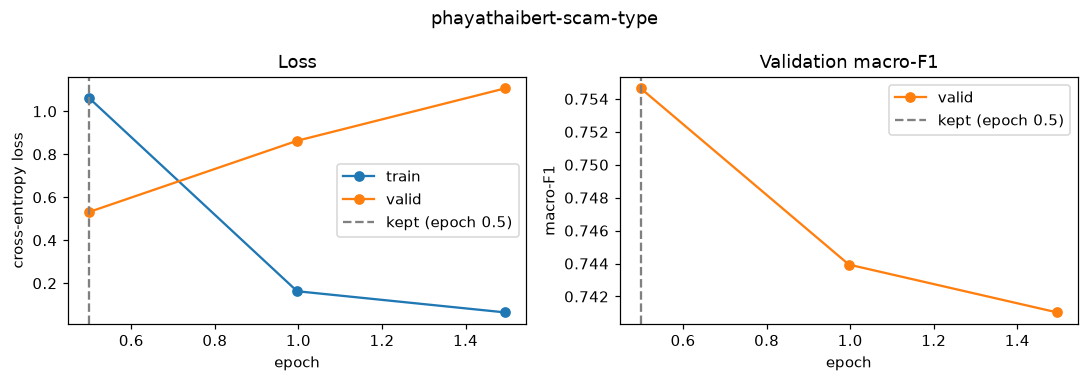

stopped at epoch 1.5 of 4, best eval_macro_f1 0.755


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.32s/it]


In [27]:
type_trainer = fine_tune(
    "phayathaibert-scam-type", typed["train"], typed["valid"], "type", TYPE_LABELS, TYPE_EPOCHS
)
type_test_pred = predict_ids(type_trainer, typed["test"])
TYPE_DIR = save(type_trainer, "phayathaibert-scam-type")
del type_trainer
torch.cuda.empty_cache()

## Step 11b. Fine-tune BGE-M3

`BAAI/bge-m3` is a multilingual XLM-RoBERTa-large encoder (24 layers, 568M parameters) that reads
up to 8192 tokens. It trains on the same rows as PhayaThaiBERT, so the two compare fairly; rows
step 6b cut stay cut. It is about twice as big, so it trains with a batch of 8 over 2
accumulation steps (16 rows per update, as PhayaThaiBERT) and gradient checkpointing to fit in
16 GB. The models go to `models/bge-m3-scam-gate` and `-type`; the live app keeps PhayaThaiBERT.
Cross-validation (step 12) stays PhayaThaiBERT only, for WangchanBERTa too.

BAAI/bge-m3: longest train row 534 tokens, at most 1024


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 18516.74it/s]


Step,Training Loss,Validation Loss,Macro F1,Accuracy
475,0.634863,0.193696,0.939590,0.945374
950,0.338674,0.250675,0.945561,0.950742
1425,0.203806,0.324916,0.924023,0.929902


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.03s/it]


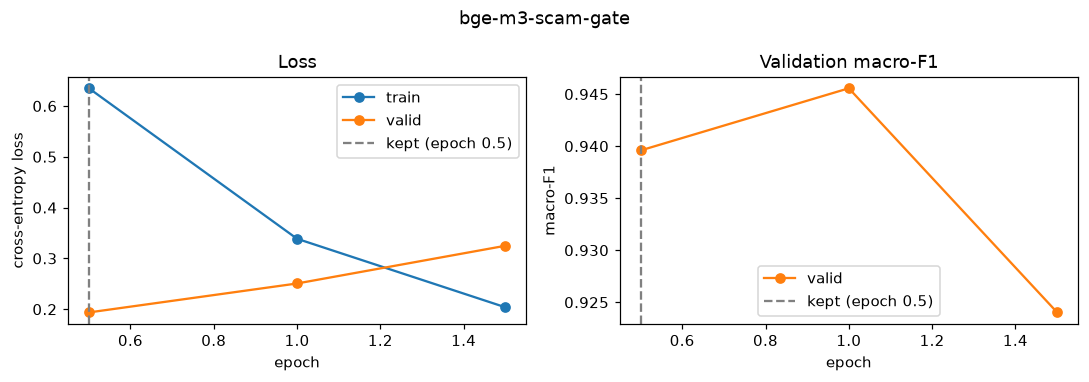

stopped at epoch 1.5 of 4, best eval_loss 0.194


In [28]:
BGE_ID = "BAAI/bge-m3"
BGE_MAX_LENGTH = 1024  # step 6b rows are at most about 600 BGE-M3 tokens
BGE_BATCH_SIZE = 8
BGE_EVAL_BATCH_SIZE = 32
BGE_ACCUMULATION_STEPS = 2
BGE_LEARNING_RATES = {"gate": 2e-5, "type": 1e-5}

BGE_M3 = Backbone(
    BGE_ID, AutoTokenizer.from_pretrained(BGE_ID), BGE_MAX_LENGTH, space_token=None,
    learning_rates=BGE_LEARNING_RATES, batch_size=BGE_BATCH_SIZE,
    eval_batch_size=BGE_EVAL_BATCH_SIZE, accumulation_steps=BGE_ACCUMULATION_STEPS,
    gradient_checkpointing=True,
)  # fmt: skip
bge_tokens = pd.Series([len(ids) for ids in BGE_M3.encode(data["train"]["text"])["input_ids"]])
print(f"{BGE_ID}: longest train row {bge_tokens.max()} tokens, at most {BGE_MAX_LENGTH}")

bge_gate_trainer = fine_tune(
    "bge-m3-scam-gate", data["train"], data["valid"], "gate", GATE_LABELS, GATE_EPOCHS,
    backbone=BGE_M3,
)  # fmt: skip

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 15797.68it/s]


Step,Training Loss,Validation Loss,Macro F1,Accuracy
164,1.568185,0.322327,0.918028,0.921833
328,0.169440,0.570475,0.897958,0.901168
492,0.069384,0.730778,0.873332,0.874214


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.09s/it]


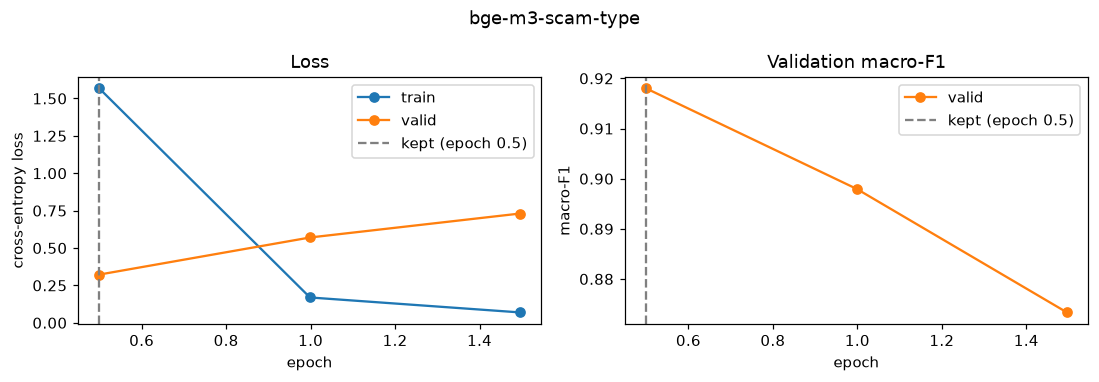

stopped at epoch 1.5 of 4, best eval_macro_f1 0.918


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.35s/it]


In [29]:
bge_gate_test_logits = predict_logits(bge_gate_trainer, data["test"], BGE_M3)
bge_gate_test_pred = bge_gate_test_logits.argmax(axis=-1)
bge_gate_test_scam = softmax(bge_gate_test_logits.astype(np.float32), axis=-1)[:, 1]
bge_gate_valid_logits = predict_logits(bge_gate_trainer, data["valid"], BGE_M3)
bge_gate_valid_scam = softmax(bge_gate_valid_logits.astype(np.float32), axis=-1)[:, 1]
save(bge_gate_trainer, "bge-m3-scam-gate", BGE_M3)
del bge_gate_trainer
torch.cuda.empty_cache()

bge_type_trainer = fine_tune(
    "bge-m3-scam-type", typed["train"], typed["valid"], "type", TYPE_LABELS, TYPE_EPOCHS,
    backbone=BGE_M3,
)  # fmt: skip
bge_type_test_pred = predict_ids(bge_type_trainer, typed["test"], BGE_M3)
save(bge_type_trainer, "bge-m3-scam-type", BGE_M3)
del bge_type_trainer
torch.cuda.empty_cache()

## Step 11c. Fine-tune WangchanBERTa

`airesearch/wangchanberta-base-att-spm-uncased` is the Thai RoBERTa-base (12 layers, 106M
parameters) that PhayaThaiBERT grew from: the same size, a smaller vocabulary and Thai-only
pretraining text. It trains on the same rows with PhayaThaiBERT's settings. Its vocabulary is
uncased, so rows are lowercased (`B:` and `[ORG]` are unknown tokens otherwise). It reads 510
tokens, as many as the longest step 6b row. The models go to `models/wangchanberta-scam-gate`
and `-type`.

airesearch/wangchanberta-base-att-spm-uncased: longest train row 510 tokens, at most 510; 0 unknown tokens


D:\text_analytics\Callas\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in D:\cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
D:\text_analytics\Callas\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to e

Step,Training Loss,Validation Loss,Macro F1,Accuracy
475,0.325986,0.208868,0.936987,0.943795
950,0.158370,0.152412,0.953333,0.958004
1425,0.078396,0.266749,0.933891,0.939691
1900,0.066253,0.257265,0.948866,0.953584


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.44it/s]


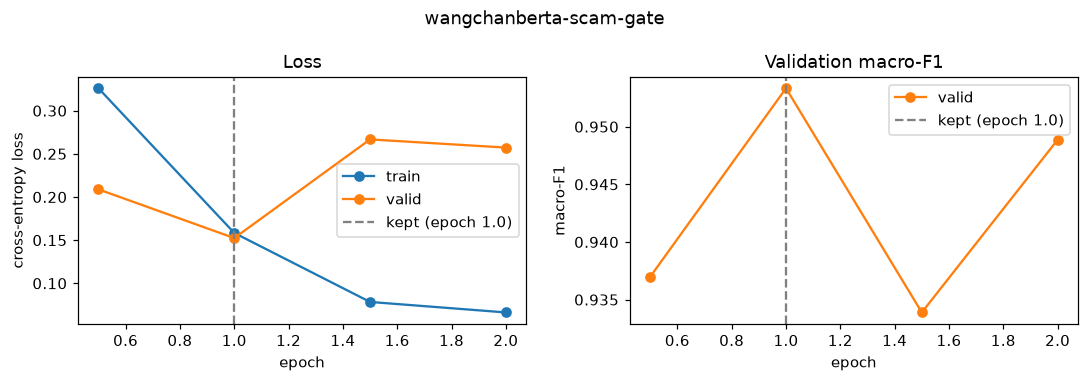

stopped at epoch 2.0 of 4, best eval_loss 0.152


In [30]:
WANGCHAN_ID = "airesearch/wangchanberta-base-att-spm-uncased"
WANGCHAN_MAX_LENGTH = 510  # 512 positions, 2 kept by RoBERTa's padding offset

WANGCHANBERTA = Backbone(
    WANGCHAN_ID, AutoTokenizer.from_pretrained(WANGCHAN_ID), WANGCHAN_MAX_LENGTH,
    space_token=SPACE_TOKEN, learning_rates=LEARNING_RATES, lowercase=True,
)  # fmt: skip
encoded = WANGCHANBERTA.encode(data["train"]["text"])["input_ids"]
wangchan_tokens = pd.Series([len(ids) for ids in encoded])
unknown = sum(ids.count(WANGCHANBERTA.tokenizer.unk_token_id) for ids in encoded)
print(
    f"{WANGCHAN_ID}: longest train row {wangchan_tokens.max()} tokens, "
    f"at most {WANGCHAN_MAX_LENGTH}; {unknown} unknown tokens"
)

wangchan_gate_trainer = fine_tune(
    "wangchanberta-scam-gate", data["train"], data["valid"], "gate", GATE_LABELS, GATE_EPOCHS,
    backbone=WANGCHANBERTA,
)  # fmt: skip

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 907.98it/s]


Step,Training Loss,Validation Loss,Macro F1,Accuracy
164,1.188093,0.546333,0.759240,0.758311
328,0.233336,0.473042,0.833444,0.832884
492,0.094332,1.017152,0.723236,0.748428
656,0.021225,0.611480,0.849407,0.850854
820,0.008396,0.614940,0.860491,0.861635
984,0.004372,0.774673,0.819832,0.820305
1148,0.002687,0.861762,0.809880,0.812219


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.49it/s]


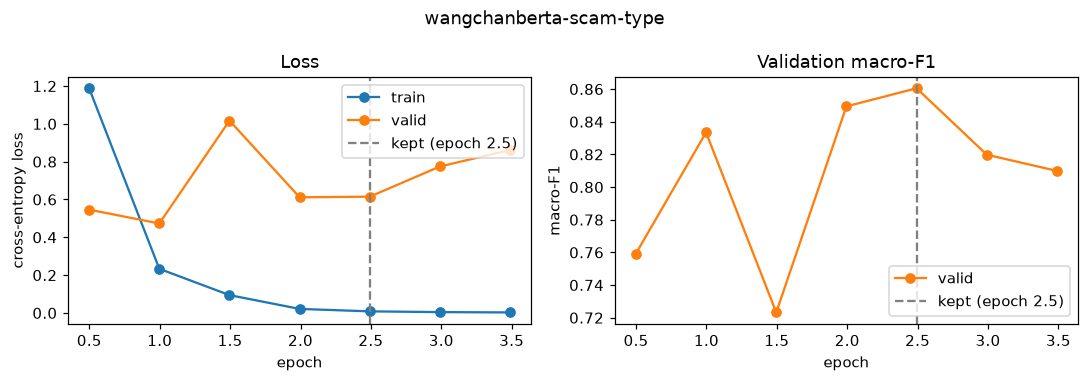

stopped at epoch 3.5 of 4, best eval_macro_f1 0.860


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.26it/s]


In [31]:
wangchan_gate_test_logits = predict_logits(wangchan_gate_trainer, data["test"], WANGCHANBERTA)
wangchan_gate_test_pred = wangchan_gate_test_logits.argmax(axis=-1)
wangchan_gate_test_scam = softmax(wangchan_gate_test_logits.astype(np.float32), axis=-1)[:, 1]
wangchan_gate_valid_logits = predict_logits(wangchan_gate_trainer, data["valid"], WANGCHANBERTA)
wangchan_gate_valid_scam = softmax(wangchan_gate_valid_logits.astype(np.float32), axis=-1)[:, 1]
save(wangchan_gate_trainer, "wangchanberta-scam-gate", WANGCHANBERTA)
del wangchan_gate_trainer
torch.cuda.empty_cache()

wangchan_type_trainer = fine_tune(
    "wangchanberta-scam-type", typed["train"], typed["valid"], "type", TYPE_LABELS, TYPE_EPOCHS,
    backbone=WANGCHANBERTA,
)  # fmt: skip
wangchan_type_test_pred = predict_ids(wangchan_type_trainer, typed["test"], WANGCHANBERTA)
save(wangchan_type_trainer, "wangchanberta-scam-type", WANGCHANBERTA)
del wangchan_type_trainer
torch.cuda.empty_cache()

## Step 12. Stratified group k-fold cross-validation

Train and valid are pooled and cut into `N_FOLDS` folds, stratified by label and grouped by
scenario. Each fold is scored once
by models that never saw it; PhayaThaiBERT picks its epoch on the next fold. Test stays out.

Each dot is a fold and the bar is the mean. Overlapping dots mean the folds do not show one
model is better. `RUN_BERT_CV = False` skips the extra fine-tunes.

scam_gate: fold 1 of 5 done
scam_gate: fold 2 of 5 done
scam_gate: fold 3 of 5 done
scam_gate: fold 4 of 5 done
scam_gate: fold 5 of 5 done
scam_type: fold 1 of 5 done
scam_type: fold 2 of 5 done
scam_type: fold 3 of 5 done
scam_type: fold 4 of 5 done
scam_type: fold 5 of 5 done


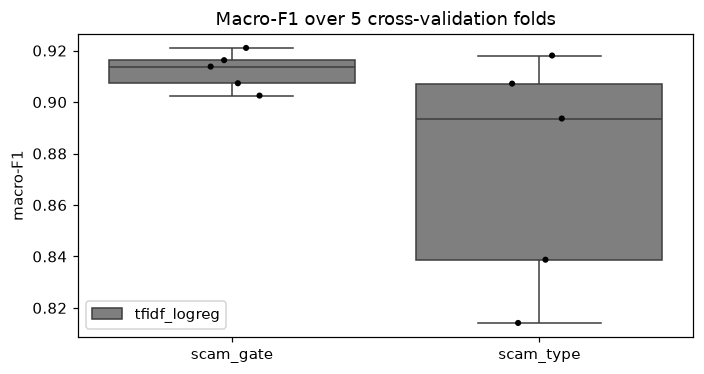

,task,model,mean,std,min,max
0,scam_gate,tfidf_logreg,0.912,0.007,0.903,0.921
1,scam_type,tfidf_logreg,0.874,0.045,0.814,0.918


In [32]:
N_FOLDS = 5
RUN_BERT_CV = False


def cross_validate(
    task: str, frame: pd.DataFrame, label_col: str, label_names: list[str], epochs: int
) -> pd.DataFrame:
    """Score each model's macro-F1 on each held-out fold."""
    frame = frame.reset_index(drop=True)
    splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    folds = [held for _, held in splitter.split(frame, frame[label_col], frame["group"])]
    ids = list(range(len(label_names)))
    rows = []
    for k, held in enumerate(folds):
        fit = frame.drop(index=held)
        baseline = make_baseline().fit(fit["text"], fit[label_col])
        predictions = {"tfidf_logreg": baseline.predict(frame.loc[held, "text"])}
        if RUN_BERT_CV and RETRAIN:
            select = folds[(k + 1) % N_FOLDS]  # picks the best epoch, never scored
            predictions["phayathaibert"] = fold_predictions(
                f"cv-{task}-fold{k + 1}", fit.drop(index=select), frame.loc[select],
                frame.loc[held], label_col, label_names, epochs,
            )  # fmt: skip
        for model, y_pred in predictions.items():
            f1 = f1_score(
                frame.loc[held, label_col], y_pred, labels=ids, average="macro", zero_division=0
            )
            rows.append(
                {"task": task, "model": model, "fold": k + 1, "samples": len(held), "macro_f1": f1}
            )
        print(f"{task}: fold {k + 1} of {N_FOLDS} done")
    return pd.DataFrame(rows)


def fold_predictions(name, train, select, held, label_col, label_names, epochs) -> np.ndarray:
    """Fine-tune on one fold's rows, predict its held-out rows, then free the GPU."""
    trainer = fine_tune(name, train, select, label_col, label_names, epochs, show=False)
    predicted = predict_ids(trainer, held)
    del trainer
    torch.cuda.empty_cache()
    shutil.rmtree(CHECKPOINTS / name, ignore_errors=True)
    return predicted


if RUN_BERT_CV and not RETRAIN:
    print("RETRAIN is False: cross-validation scores the TF-IDF baseline only")
cv_scores = pd.concat(
    [
        cross_validate(
            "scam_gate", pd.concat([data["train"], data["valid"]]), "gate", GATE_LABELS,
            GATE_EPOCHS,
        ),
        cross_validate(
            "scam_type", pd.concat([typed["train"], typed["valid"]]), "type", TYPE_LABELS,
            TYPE_EPOCHS,
        ),
    ],
    ignore_index=True,
)  # fmt: skip

cv_models = [model for model in MODEL_COLORS if model in set(cv_scores["model"])]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
sns.boxplot(
    data=cv_scores, x="task", y="macro_f1", hue="model", hue_order=cv_models,
    palette=MODEL_COLORS, ax=ax,
)  # fmt: skip
sns.stripplot(
    data=cv_scores, x="task", y="macro_f1", hue="model", hue_order=cv_models, dodge=True,
    palette={model: "black" for model in cv_models}, size=4, legend=False, ax=ax,
)  # fmt: skip
ax.set(title=f"Macro-F1 over {N_FOLDS} cross-validation folds", xlabel="", ylabel="macro-F1")
ax.legend(title=None)
plt.tight_layout()
save_chart("step12_cv_folds")

cv_summary = (
    cv_scores.groupby(["task", "model"])["macro_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(3)
    .reset_index()
)
save_table(cv_summary, "step12_cv_summary")
cv_summary.style.format(precision=3).bar(subset=["mean"], vmin=0, vmax=1, color="#b7d3f6")

## Step 13. Test set evaluation

The fine-tuned models through `score` (macro-averaged precision, recall and F1 with a bootstrap
confidence interval): the numbers the spec asks for. If they differ much
from the cross-validation mean, trust cross-validation, which rests on more rows.

In [33]:
score(
    "scam_gate", "phayathaibert", data["test"]["gate"], gate_test_pred, GATE_LABELS,
    data["test"]["call_id"],
)  # fmt: skip
score(
    "scam_gate", "bge_m3", data["test"]["gate"], bge_gate_test_pred, GATE_LABELS,
    data["test"]["call_id"],
)  # fmt: skip
score(
    "scam_gate", "wangchanberta", data["test"]["gate"], wangchan_gate_test_pred, GATE_LABELS,
    data["test"]["call_id"],
)  # fmt: skip
score(
    "scam_type", "phayathaibert", typed["test"]["type"], type_test_pred, TYPE_LABELS,
    typed["test"]["call_id"],
)  # fmt: skip
score(
    "scam_type", "bge_m3", typed["test"]["type"], bge_type_test_pred, TYPE_LABELS,
    typed["test"]["call_id"],
)  # fmt: skip
score(
    "scam_type", "wangchanberta", typed["test"]["type"], wangchan_type_test_pred, TYPE_LABELS,
    typed["test"]["call_id"],
)  # fmt: skip

=== scam_gate / phayathaibert ===
              precision    recall  f1-score   support

    not_scam      0.956     0.969     0.963      2031
        scam      0.943     0.919     0.931      1113

    accuracy                          0.952      3144
   macro avg      0.950     0.944     0.947      3144
weighted avg      0.952     0.952     0.952      3144

macro-F1 95% bootstrap interval: 0.933 to 0.959

=== scam_gate / bge_m3 ===
              precision    recall  f1-score   support

    not_scam      0.946     0.958     0.952      2031
        scam      0.922     0.900     0.911      1113

    accuracy                          0.938      3144
   macro avg      0.934     0.929     0.931      3144
weighted avg      0.937     0.938     0.937      3144

macro-F1 95% bootstrap interval: 0.916 to 0.946

=== scam_gate / wangchanberta ===
              precision    recall  f1-score   support

    not_scam      0.949     0.983     0.966      2031
        scam      0.967     0.904     0.935 

### Gate: ROC and precision-recall curves

Every threshold at once, on the same test rows. Scam rows are the smaller class, so read the
precision-recall curve and its average precision (AP) first. ROC AUC is the chance a scam row
scores above a normal row. The dashed line is a model that guesses.

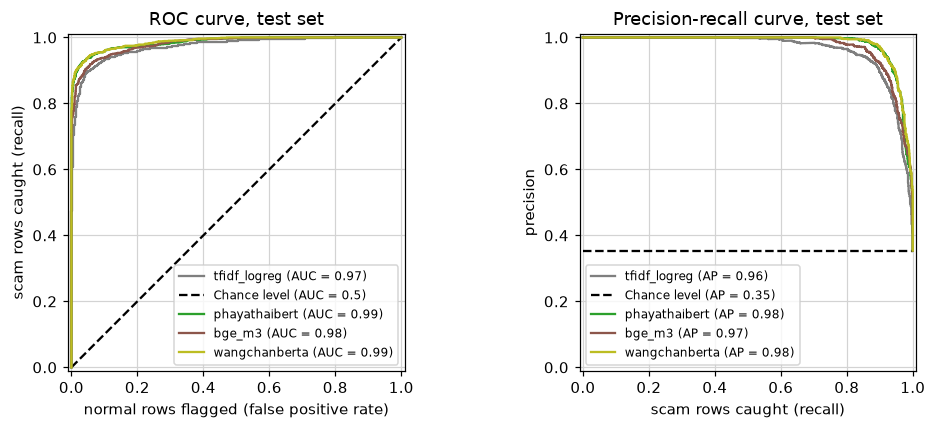

,roc_auc,average_precision
tfidf_logreg,0.973,0.963
phayathaibert,0.986,0.981
bge_m3,0.981,0.973
wangchanberta,0.987,0.982


In [34]:
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    roc_auc_score,
)

y_test = data["test"]["gate"]
gate_scores = {
    "tfidf_logreg": gate_baseline.predict_proba(data["test"]["text"])[:, 1],
    "phayathaibert": gate_test_scam,
    "bge_m3": bge_gate_test_scam,
    "wangchanberta": wangchan_gate_test_scam,
}

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for model, scores in gate_scores.items():
    first = model == "tfidf_logreg"
    RocCurveDisplay.from_predictions(
        y_test,
        scores,
        name=model,
        curve_kwargs={"color": MODEL_COLORS[model]},
        plot_chance_level=first,
        ax=axes[0],
    )
    PrecisionRecallDisplay.from_predictions(
        y_test,
        scores,
        name=model,
        curve_kwargs={"color": MODEL_COLORS[model]},
        plot_chance_level=first,
        ax=axes[1],
    )
axes[0].set(
    title="ROC curve, test set",
    xlabel="normal rows flagged (false positive rate)",
    ylabel="scam rows caught (recall)",
)
axes[1].set(
    title="Precision-recall curve, test set", xlabel="scam rows caught (recall)", ylabel="precision"
)
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[1] else "lower right", fontsize=8)
    ax.grid(color="lightgray", linewidth=0.8)
plt.tight_layout()
save_chart("step13_gate_roc_pr")

gate_curves = pd.DataFrame(
    {
        model: {
            "roc_auc": roc_auc_score(y_test, scores),
            "average_precision": average_precision_score(y_test, scores),
        }
        for model, scores in gate_scores.items()
    }
).T.round(3)
save_table(gate_curves, "step13_gate_curves")

### Gate: threshold, calibration and McNemar test

- Calibration: the reliability diagram and Brier score. A curve on the diagonal means
  P(scam) = 0.8 is right 8 times in 10, which `GATE_MIN_CONFIDENCE` assumes.
- McNemar's exact test (PhayaThaiBERT vs TF-IDF, BGE-M3 and WangchanBERTa vs PhayaThaiBERT) on the test rows
  only one of the two models gets right. Rows of one call
  are not independent, so read the p-value as optimistic.

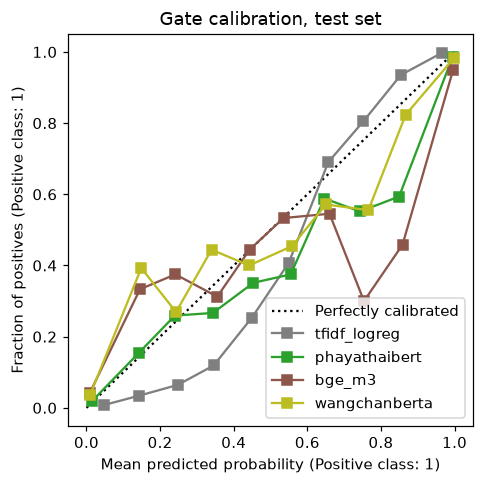

McNemar phayathaibert vs tfidf_logreg: only phayathaibert right on 136 rows, only tfidf_logreg on 51, p = 4.07e-10
McNemar bge_m3 vs phayathaibert: only bge_m3 right on 48 rows, only phayathaibert on 92, p = 0.000251
McNemar wangchanberta vs phayathaibert: only wangchanberta right on 54 rows, only phayathaibert on 43, p = 0.31


tfidf_logreg     0.066042
phayathaibert    0.037463
bge_m3           0.053791
wangchanberta    0.038076
Name: brier score (test), dtype: float64

In [35]:
from scipy.stats import binomtest
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

valid_scores = {
    "tfidf_logreg": gate_baseline.predict_proba(data["valid"]["text"])[:, 1],
    "phayathaibert": gate_valid_scam,
    "bge_m3": bge_gate_valid_scam,
    "wangchanberta": wangchan_gate_valid_scam,
}
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for model, scores in gate_scores.items():
    CalibrationDisplay.from_predictions(
        y_test, scores, n_bins=10, name=model, color=MODEL_COLORS[model], ax=ax
    )
ax.set(title="Gate calibration, test set")
plt.tight_layout()
save_chart("step13_gate_calibration")

mcnemar_p = {}
for first, second in (
    ("phayathaibert", "tfidf_logreg"),
    ("bge_m3", "phayathaibert"),
    ("wangchanberta", "phayathaibert"),
):
    y_true, first_pred = predictions[("scam_gate", first)]
    second_pred = predictions[("scam_gate", second)][1]
    only_first = int(((first_pred == y_true) & (second_pred != y_true)).sum())
    only_second = int(((second_pred == y_true) & (first_pred != y_true)).sum())
    disagree = only_first + only_second
    p_value = binomtest(only_first, disagree).pvalue if disagree else 1.0
    mcnemar_p[f"{first} vs {second}"] = float(p_value)
    print(
        f"McNemar {first} vs {second}: only {first} right on {only_first} rows, "
        f"only {second} on {only_second}, p = {p_value:.3g}"
    )
save_table(
    pd.Series(
        {model: brier_score_loss(y_test, scores) for model, scores in gate_scores.items()},
        name="brier score (test)",
    ),
    "step13_gate_calibration_table",
)

### All models side by side

The confusion matrices of the trivial baselines, the TF-IDF baseline, PhayaThaiBERT, BGE-M3 and
WangchanBERTa on the same test rows, each normalized by the actual class.

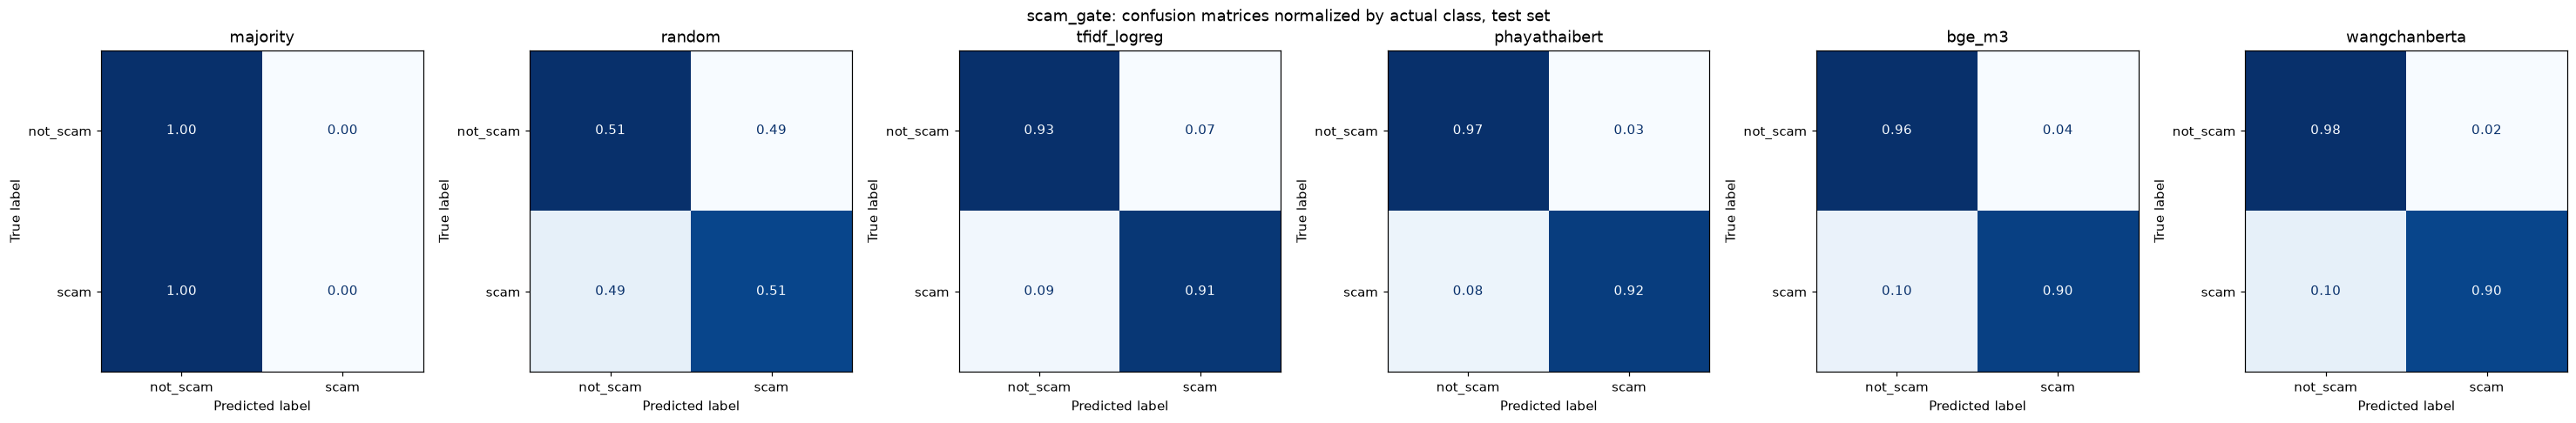

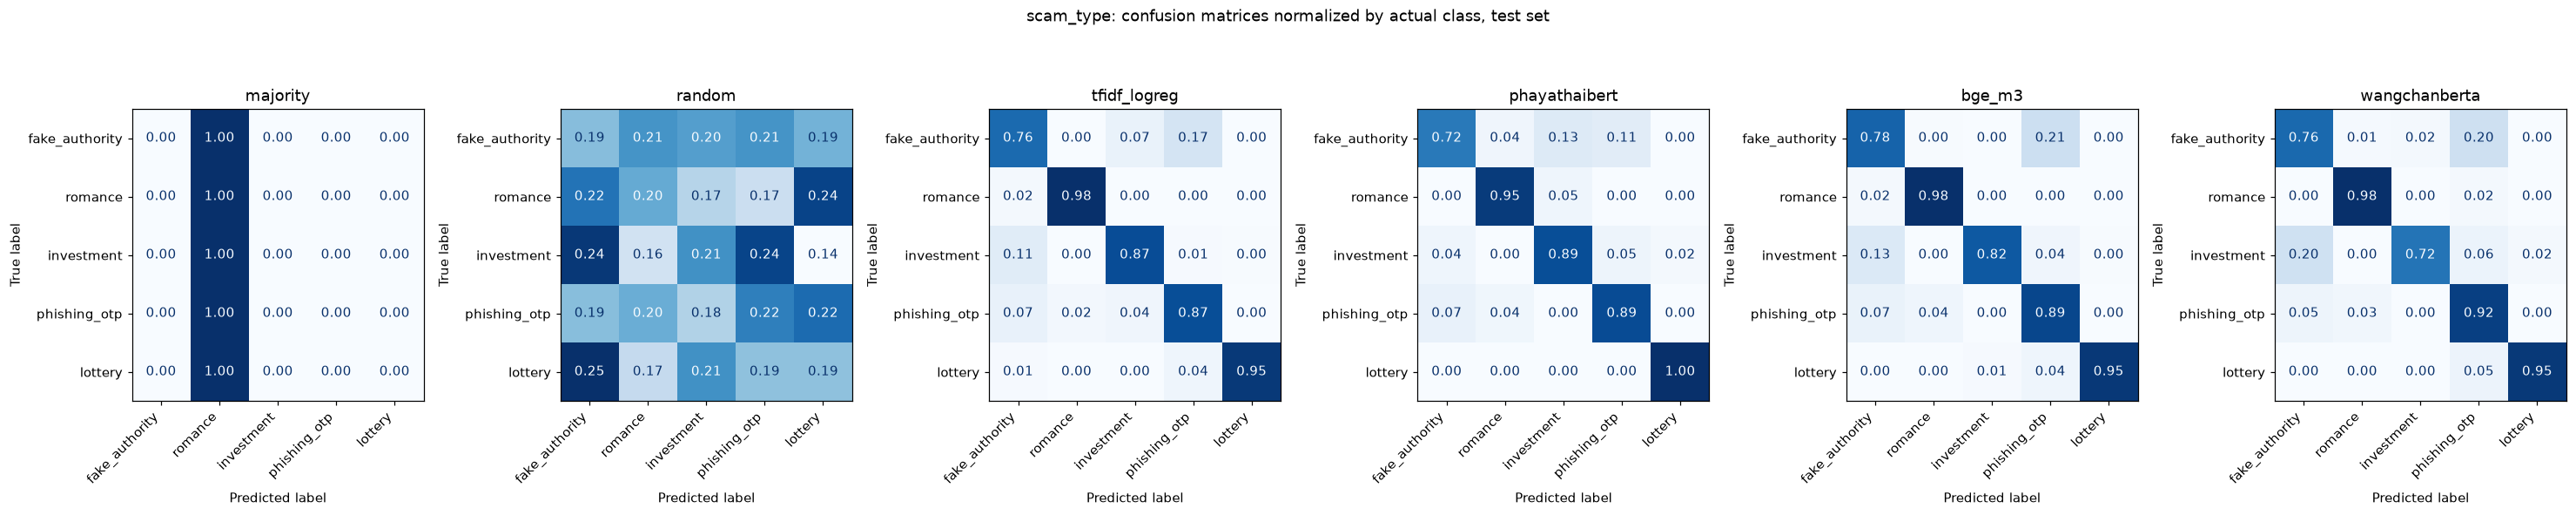

In [36]:
plot_confusion_matrices("scam_gate", GATE_LABELS, "step13_confusion_scam_gate")
plot_confusion_matrices("scam_type", TYPE_LABELS, "step13_confusion_scam_type")

### Extra evaluation

- Gate recall by how a scam call ends (`scam_outcome`).
- Gate per call: scam calls caught, turns from `scam_start_turn` to the first alarm (the spec
  asks for at most `CAUGHT_WITHIN`), and normal calls flagged.
- The last cell writes every score to `models/scam_classifier_metrics.json` and draws
  macro-F1 per task.

In [37]:
CAUGHT_WITHIN = 1  # turns after scam_start_turn, from the spec's call memory test


def recall_by_outcome(frame: pd.DataFrame, pred) -> pd.DataFrame:
    """Count the scam rows the gate caught (pred 1), by scam_outcome and all together."""
    caught = pd.Series(np.asarray(pred) == 1, index=frame.index)
    scams = frame["label_scam"].astype(bool)
    outcome = frame["scam_outcome"].fillna("none")
    groups = {name: scams & (outcome == name) for name in ("scammed", "safe")}
    groups["all scams"] = scams
    rows = {}
    for name, rows_in in groups.items():
        calls = int(rows_in.sum())
        rows[name] = {
            "calls": calls,
            "caught": int(caught[rows_in].sum()),
            "recall": float(caught[rows_in].mean()) if calls else float("nan"),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def alarms_per_call(frame: pd.DataFrame, pred) -> pd.DataFrame:
    """One row per call: is it a scam, the turns from its start to the gate's first scam answer,
    and whether the gate flagged one of its safe rows."""
    rows = frame.assign(flagged=np.asarray(pred) == 1)
    start = rows[rows["label_scam"]].groupby("call_id")["turn_index"].min()
    caught = rows[rows["label_scam"] & rows["flagged"]].groupby("call_id")["turn_index"].min()
    return pd.DataFrame(
        {
            "is_scam": rows.groupby("call_id")["label_scam"].any(),
            "delay": caught - start,
            "false_alarm": (rows["flagged"] & ~rows["label_scam"]).groupby(rows["call_id"]).any(),
        }
    )


def call_summary(calls: pd.DataFrame) -> dict:
    """Sum up alarms_per_call: scam calls caught, how fast, and normal calls flagged."""
    scams, normal = calls[calls["is_scam"]], calls[~calls["is_scam"]]
    return {
        "scam calls": len(scams),
        "caught": scams["delay"].notna().mean(),
        f"caught within {CAUGHT_WITHIN} turn": (scams["delay"] <= CAUGHT_WITHIN).mean(),
        "median delay (turns)": scams["delay"].median(),
        "flagged before the start": scams["false_alarm"].mean(),
        "normal calls": len(normal),
        "normal calls flagged": normal["false_alarm"].mean(),
    }

### Does the gate catch scams where the receiver goes along?

`scammed`: the receiver goes along. `safe`: the receiver refuses. Clearly lower recall on
`scammed` means the gate leans on the refusal and would miss real victims. The second table
splits PhayaThaiBERT's recall by type.

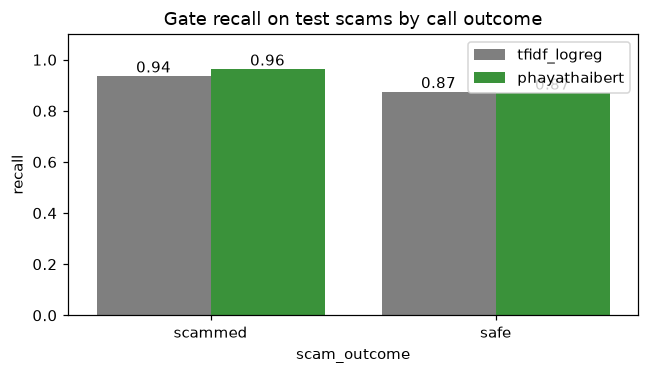

=== PhayaThaiBERT recall by type and outcome ===
                scammed   safe  all scams
fake_authority    0.961  0.818      0.887
investment        0.878  0.651      0.781
lottery           0.978  0.933      0.956
phishing_otp      0.985  0.934      0.961
romance           1.000  0.964      0.985


tfidf_logreg                  phayathaibert                 
                 calls caught    recall         calls caught    recall
scammed            594    556  0.936027           594    572  0.962963
safe               519    454  0.874759           519    451  0.868979
all scams         1113   1010  0.907457          1113   1023  0.919137

In [38]:
outcome_recall = pd.concat(
    {
        "tfidf_logreg": recall_by_outcome(data["test"], gate_baseline_test_pred),
        "phayathaibert": recall_by_outcome(data["test"], gate_test_pred),
    },
    axis=1,
)

test = data["test"]
gate_pred = np.asarray(gate_test_pred)
recall_by_type = pd.DataFrame(
    {
        label_type: recall_by_outcome(test[rows], gate_pred[rows.to_numpy()])["recall"]
        for label_type in sorted(set(test.loc[test["label_scam"], "label_type"].dropna()))
        for rows in [test["label_type"] == label_type]
    }
).T

recall = outcome_recall.xs("recall", axis=1, level=1).loc[["scammed", "safe"]]
recall_long = (
    recall.rename_axis("outcome")
    .reset_index()
    .melt(id_vars="outcome", var_name="model", value_name="recall")
)
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(data=recall_long, x="outcome", y="recall", hue="model", palette=MODEL_COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
ax.set(title="Gate recall on test scams by call outcome", xlabel="scam_outcome", ylim=(0, 1.1))
ax.legend(title=None)
plt.tight_layout()
save_chart("step13_recall_by_outcome")

print("=== PhayaThaiBERT recall by type and outcome ===")
print(save_table(recall_by_type.round(3), "step13_recall_by_type").to_string())
save_table(outcome_recall, "step13_recall_by_outcome_table")

### Gate per call

The app acts on the first alarm in a call, so this table scores calls, not rows: how many scam
calls the gate catches, how many turns after `scam_start_turn`, and how many normal calls it
flags at least once. The argmax columns cut at 0.5. The `cut` columns use the lowest cut on
P(scam) that flags at most `MAX_NORMAL_FLAGGED` of the normal calls in valid. The live app
answers scam above P(scam) 0.4 (`GATE_MIN_CONFIDENCE` 0.6), so copy the cut there to use it.

In [39]:
MAX_NORMAL_FLAGGED = 0.05


def call_cut(frame: pd.DataFrame, scam_scores: np.ndarray) -> float:
    """The lowest cut on P(scam) that flags at most MAX_NORMAL_FLAGGED of the normal calls."""
    rows = frame.assign(score=scam_scores)
    normal = ~rows.groupby("call_id")["label_scam"].transform("any")
    top = np.sort(rows[normal].groupby("call_id")["score"].max().to_numpy())[::-1]
    return float(np.nextafter(top[int(MAX_NORMAL_FLAGGED * len(top))], 1))


call_cuts = {model: call_cut(data["valid"], scores) for model, scores in valid_scores.items()}
argmax_preds = {
    "tfidf_logreg": gate_baseline_test_pred,
    "phayathaibert": gate_test_pred,
    "bge_m3": bge_gate_test_pred,
    "wangchanberta": wangchan_gate_test_pred,
}
call_level = pd.DataFrame(
    {
        **{
            model: call_summary(alarms_per_call(data["test"], pred))
            for model, pred in argmax_preds.items()
        },
        **{
            f"{model}, cut {cut:.3f}": call_summary(
                alarms_per_call(data["test"], (gate_scores[model] >= cut).astype(int))
            )
            for model, cut in call_cuts.items()
        },
    }
)
print("=== Gate per call, test set ===")
print(save_table(call_level.round(3), "step13_gate_per_call").to_string())

=== Gate per call, test set ===
                          tfidf_logreg  phayathaibert   bge_m3  wangchanberta  tfidf_logreg, cut 0.575  phayathaibert, cut 0.182  bge_m3, cut 0.467  wangchanberta, cut 0.032
scam calls                     233.000        233.000  233.000        233.000                  233.000                   233.000            233.000                   233.000
caught                           0.983          0.944    0.918          0.957                    0.970                     0.979              0.923                     0.987
caught within 1 turn             0.888          0.884    0.850          0.867                    0.837                     0.936              0.854                     0.957
median delay (turns)             0.000          0.000    0.000          0.000                    0.000                     0.000              0.000                     0.000
flagged before the start         0.202          0.129    0.163          0.056                    0

### Gate by data source

The calls Claude Sonnet wrote (`dataset/sonnet_*.jsonl`, ids with `_sonnet_`) avoid the template
openings and words of the first generator. Each model's test macro-F1 on each source, for the gate and
the type model, shows whether they still work without those shortcuts. Sonnet calls are few, so read the rows count too.

In [40]:
def macro_f1_by_source(task: str, frame: pd.DataFrame) -> pd.DataFrame:
    """Each model's test macro-F1 on the existing calls and on the Sonnet calls."""
    is_sonnet = frame["call_id"].str.contains("_sonnet_").to_numpy()
    sources = {"existing": ~is_sonnet, "sonnet": is_sonnet}
    table = pd.DataFrame(
        {
            model: {
                source: f1_score(y_true[rows], y_pred[rows], average="macro", zero_division=0)
                for source, rows in sources.items()
                if rows.any()
            }
            for (name, model), (y_true, y_pred) in predictions.items()
            if name == task
        }
    )
    return table.assign(
        rows=pd.Series({source: int(rows.sum()) for source, rows in sources.items()})
    )


for task, frame in (("scam_gate", data["test"]), ("scam_type", typed["test"])):
    print(f"=== {task} macro-F1 by data source, test set ===")
    print(
        save_table(macro_f1_by_source(task, frame).round(3), f"step13_{task}_by_source").to_string()
    )

=== scam_gate macro-F1 by data source, test set ===
          tfidf_logreg  majority  random  phayathaibert  bge_m3  wangchanberta  rows
existing         0.915     0.376   0.519          0.935   0.915          0.949  1824
sonnet           0.921     0.413   0.473          0.964   0.956          0.951  1320
=== scam_type macro-F1 by data source, test set ===
          tfidf_logreg  majority  random  phayathaibert  bge_m3  wangchanberta  rows
existing         0.943     0.086   0.199          0.956   0.912          0.896   723
sonnet           0.789     0.056   0.197          0.770   0.831          0.820   390


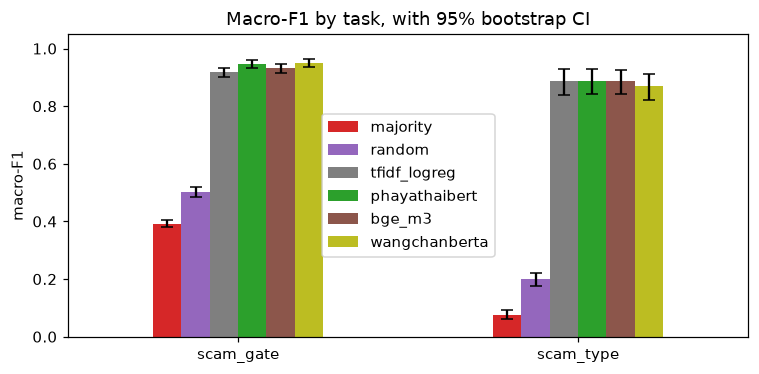

,task,model,precision,recall,f1,f1_ci_low,f1_ci_high,accuracy,n_test
0,scam_gate,bge_m3,0.934,0.929,0.931,0.915,0.946,0.938,3144
1,scam_gate,majority,0.323,0.500,0.393,0.380,0.405,0.646,3144
2,scam_gate,phayathaibert,0.950,0.944,0.947,0.933,0.959,0.952,3144
3,scam_gate,random,0.511,0.512,0.501,0.483,0.519,0.513,3144
4,scam_gate,tfidf_logreg,0.916,0.921,0.918,0.901,0.934,0.925,3144
5,scam_gate,wangchanberta,0.958,0.944,0.950,0.936,0.963,0.955,3144
6,scam_type,bge_m3,0.899,0.883,0.889,0.843,0.927,0.887,1113
7,scam_type,majority,0.047,0.200,0.076,0.061,0.092,0.236,1113
8,scam_type,phayathaibert,0.890,0.890,0.889,0.842,0.930,0.890,1113
9,scam_type,random,0.201,0.200,0.199,0.175,0.220,0.200,1113


In [41]:
metrics = {
    "model_id": MODEL_ID,
    "bge_model_id": BGE_ID,
    "wangchanberta_model_id": WANGCHAN_ID,
    "seed": SEED,
    "samples": {name: int(len(frame)) for name, frame in data.items()},
    "type_labels": TYPE_LABELS,
    "cross_validation": {
        "folds": N_FOLDS,
        "pool": "train + valid",
        "macro_f1": cv_summary.to_dict(orient="records"),
    },
    "gate_baseline_valid_f1_by_input": speaker_f1.round(4).to_dict(),
    "results": results,
    "gate_curves": gate_curves.to_dict(orient="index"),
    "gate_call_cut_picked_on_valid": call_cuts,
    "gate_mcnemar_p": mcnemar_p,
    "gate_per_call": call_level.astype(object).where(call_level.notna(), None).to_dict(),
}
metrics["gate_recall_by_outcome"] = {
    model: recall_by_outcome(data["test"], pred)
    .astype(object)
    .where(lambda table: table.notna(), None)
    .to_dict(orient="index")
    for model, pred in (
        ("tfidf_logreg", gate_baseline_test_pred),
        ("phayathaibert", gate_test_pred),
    )
}
MODELS.mkdir(parents=True, exist_ok=True)
(MODELS / "scam_classifier_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
)

summary = (
    pd.DataFrame(results)
    .drop(columns="per_class")
    .sort_values(["task", "model"])
    .reset_index(drop=True)
)

f1 = (
    summary.pivot(index="task", columns="model", values="f1")
    .reindex(columns=list(MODEL_COLORS))
    .dropna(axis=1, how="all")
)
bounds = {
    side: summary.pivot(index="task", columns="model", values=f"f1_ci_{side}").reindex(
        index=f1.index, columns=f1.columns
    )
    for side in ("low", "high")
}
# pandas takes asymmetric error bars as (columns, 2, rows): distance below and above each bar
errors = np.stack([(f1 - bounds["low"]).to_numpy().T, (bounds["high"] - f1).to_numpy().T], axis=1)
ax = f1.plot.bar(
    yerr=errors, capsize=4, rot=0, figsize=(7, 3.5),
    color=[MODEL_COLORS[model] for model in f1.columns],
)  # fmt: skip
ax.set(
    title="Macro-F1 by task, with 95% bootstrap CI", xlabel="", ylabel="macro-F1", ylim=(0, 1.05)
)
ax.legend(title=None)
plt.tight_layout()
save_chart("step13_macro_f1_by_task")

save_table(summary, "step13_summary")
summary.style.format(precision=3).bar(
    subset=["precision", "recall", "f1", "accuracy"], vmin=0, vmax=1, color="#b7d3f6"
)

## Step 14. Inference

`ScamClassifier.predict` follows the protocol in `nlp_core/interfaces.py` and returns
`(label_scam, label_type, confidence)`:

- gate below `GATE_MIN_CONFIDENCE`: `(True, None, 0.0)`, never safe when unsure
- `label_type` only when the gate says scam and the type model reaches `TYPE_MIN_CONFIDENCE`

Give it a step 6b row: `B` the caller, `A` the receiver, values masked as in step 1. Tune both
thresholds on valid before the app uses them.

In [42]:
from transformers import pipeline

GATE_MIN_CONFIDENCE = 0.60  # below this the answer is (True, None, 0.0)
TYPE_MIN_CONFIDENCE = 0.50  # below this the type answer is dropped


class ScamClassifier:
    """The gate and type models behind the ScamClassifier protocol of nlp_core."""

    def __init__(self, gate_dir: Path, type_dir: Path):
        self.gate = pipeline("text-classification", model=str(gate_dir), device=device)
        self.type = pipeline("text-classification", model=str(type_dir), device=device)

    def predict(self, text: str) -> tuple[bool, str | None, float]:
        """Return (label_scam, label_type, confidence) for one row of text."""
        text = to_model_text(normalize_text(text))
        gate = self.gate(text, truncation=True, max_length=MAX_LENGTH)[0]
        if gate["score"] < GATE_MIN_CONFIDENCE:
            return True, None, 0.0
        is_scam = gate["label"] == "scam"
        label_type = None
        if is_scam:
            top_type = self.type(text, truncation=True, max_length=MAX_LENGTH)[0]
            if top_type["score"] >= TYPE_MIN_CONFIDENCE:
                label_type = top_type["label"]
        return is_scam, label_type, gate["score"]


classifier = ScamClassifier(GATE_DIR, TYPE_DIR)

# First-turn rows, written as in training: B the caller, A the person called.
examples = [
    "B: ต้องโอนเงินมาให้ตรวจสอบภายในวันนี้ ห้ามวางสายและห้ามบอกใคร",
    "B: สวัสดีค่ะ โทรจากคลินิกทันตกรรมค่ะ ขอยืนยันนัดขูดหินปูนวันเสาร์สิบโมง",
    "A: ผมไม่เคยทำอะไรแบบนั้นนะครับ",
]
for text in examples:
    print(classifier.predict(text), "<-", text)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1003.66it/s]


(True, None, 0.9259089231491089) <- B: ต้องโอนเงินมาให้ตรวจสอบภายในวันนี้ ห้ามวางสายและห้ามบอกใคร
(False, None, 0.9959878325462341) <- B: สวัสดีค่ะ โทรจากคลินิกทันตกรรมค่ะ ขอยืนยันนัดขูดหินปูนวันเสาร์สิบโมง
(False, None, 0.9858111143112183) <- A: ผมไม่เคยทำอะไรแบบนั้นนะครับ
